In [1]:
# %%
import torch
import numpy as np
import pandas as pd
from pathlib import Path
from matplotlib import pyplot as plt
from torch.utils.data import TensorDataset, DataLoader
import torch.nn as nn
import torch.nn.functional as F
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.model_selection import StratifiedKFold, KFold, train_test_split
from sklearn.decomposition import PCA
import sys
import shap  # Add SHAP import for bee swarm plots


# Add project paths
models_path = Path().resolve().parents[1] / "src" / "models"
postproc_path = Path().resolve().parents[1] / "src" / "postprocessing"
sys.path.extend([str(models_path), str(postproc_path)])

# Import project modules
from trainMTL import *
from explainDNN import *
from predictDNN import *
from getModelPerformance import * 

porosity_fileidx = 83

# Set random seed for reproducibility
set_seed(42)


Using `tqdm.autonotebook.tqdm` in notebook mode. Use `tqdm.tqdm` instead to force console mode (e.g. in jupyter console)


In [2]:

# Set device and torch backend options
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
print(device)
set_seed()
constraint = 0.1
layer_widths_all = [[512]*3, [512]*4, [512]*5, [512]*6, [512]*7, [512]*8, [128]*3, [128]*4, [128]*5, [128]*6, [128]*7, [128]*8, [64]*3, [64]*4, [64]*5, [64]*6, [64]*7, [64]*8]
num_shared_layers_all = [1, 2, 3, 4, 5, 6, 7, 8]
# %%

# %% TOTAL ORGANIC CARBON
features_toc_CS = np.load("/gxfs_work/cau/sunms498/work/nn-toc-update/notebooks/TOC/preprocessed/features_CS_toc.npy")
labels_toc_CS = np.load("/gxfs_work/cau/sunms498/work/nn-toc-update/notebooks/TOC/preprocessed/labels_CS_toc.npy")
labels_mean_toc_CS = np.mean(labels_toc_CS)
labels_std_toc_CS = np.std(labels_toc_CS)

n_bins = 10
y_binned = pd.qcut(labels_toc_CS, q=n_bins, labels=False, duplicates='drop')
train_features_toc_CS, train_labels_toc_CS, test_features_toc_CS, test_labels_toc_CS = split_train_test_data(features_toc_CS, labels_toc_CS, test_size_ratio=0.25, random_seed=42, stratify=y_binned)
#trainloader, testloader = create_dataloaders(train_features, train_labels, test_features, test_labels, batch_size=batch_size, shuffle_train=True, shuffle_test=False)


features_toc_DO = np.load("/gxfs_work/cau/sunms498/work/nn-toc-update/notebooks/TOC/preprocessed/features_DO_toc.npy")
labels_toc_DO = np.load("/gxfs_work/cau/sunms498/work/nn-toc-update/notebooks/TOC/preprocessed/labels_DO_toc.npy")
labels_mean_toc_DO = np.mean(labels_toc_DO)
labels_std_toc_DO = np.std(labels_toc_DO)


y_binned = pd.qcut(labels_toc_DO, q=n_bins, labels=False, duplicates='drop')
train_features_toc_DO, train_labels_toc_DO, test_features_toc_DO, test_labels_toc_DO = split_train_test_data(features_toc_DO, labels_toc_DO, test_size_ratio=0.25, random_seed=42, stratify=y_binned)
#trainloader, testloader = create_dataloaders(train_features, train_labels, test_features, test_labels, batch_size=batch_size, shuffle_train=True, shuffle_test=False)


toc_train_features = np.concatenate([train_features_toc_CS, train_features_toc_DO], axis = 0)
toc_test_features = np.concatenate([test_features_toc_CS, test_features_toc_DO], axis = 0)
toc_train_labels = np.concatenate([train_labels_toc_CS, train_labels_toc_DO], axis = 0)
toc_test_labels = np.concatenate([test_labels_toc_CS, test_labels_toc_DO], axis = 0)

features_toc = np.concatenate([features_toc_CS, features_toc_DO], axis = 0)
labels_toc = np.concatenate([labels_toc_CS, labels_toc_DO], axis = 0)



# Load world features
dataset_path = Path("/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/interim/worldfeatures/WorldFeaturesAllnoNaN_SedTOC_predict_men/")
files = sorted([f for f in dataset_path.iterdir() if f.is_file()])
features = np.load(files[0])
world_feature_shape_dim = features.shape[1]

#MASS ACCUMULATION RATES
feature_path = Path("/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/interim/inputfeatures/SedTOCFeaturesnoNAN_MAR_DO_men/")
features = np.load(Path(feature_path / "numpy_features.npy"))
labels = np.load(Path(feature_path / "numpy_labels.npy"))
X_mean = np.load(feature_path / "features_mean.npy").astype(float)
X_std = np.load(feature_path / "features_std.npy").astype(float)
lats = np.load(feature_path / "numpy_lat.npy")
lons = np.load(feature_path / "numpy_lon.npy")
input_feature_shape_dim = features.shape[1]



if world_feature_shape_dim != input_feature_shape_dim:
    raise ValueError(f"Feature dimensions do not match: World features have {world_feature_shape_dim} dimensions while input features have {input_feature_shape_dim} dimensions")

print(f"Number of features: {features.shape[1]}")



features_DO, labels_DO, lats_DO, lons_DO = preprocess_features_labels(features, labels, lats, lons, X_mean, X_std)


from sklearn.model_selection import StratifiedKFold


test_size_ratio = 0.25
print("Test size ratio") 
print(test_size_ratio)

# Create bins for stratification
n_bins = 10
y_binned = pd.qcut(labels_DO, q=n_bins, labels=False, duplicates='drop')
train_features_DO, train_labels_DO, test_features_DO, test_labels_DO = split_train_test_data(features_DO, labels_DO, test_size_ratio=0.25, random_seed=42, stratify=y_binned)
#trainloader, testloader = create_dataloaders(train_features, train_labels, test_features, test_labels, batch_size=batch_size, shuffle_train=True, shuffle_test=False)




#  Load input feature 
feature_path = Path("/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/interim/inputfeatures/SedTOCFeaturesnoNAN_MAR_CS_men/")
features = np.load(Path(feature_path / "numpy_features.npy"))
labels = np.load(Path(feature_path / "numpy_labels.npy"))
X_mean = np.load(feature_path / "features_mean.npy").astype(float)
X_std = np.load(feature_path / "features_std.npy").astype(float)
lats = np.load(feature_path / "numpy_lat.npy")
lons = np.load(feature_path / "numpy_lon.npy")
input_feature_shape_dim = features.shape[1]


if world_feature_shape_dim != input_feature_shape_dim:
    raise ValueError(f"Feature dimensions do not match: World features have {world_feature_shape_dim} dimensions while input features have {input_feature_shape_dim} dimensions")

print(f"Number of features: {features.shape[1]}")


features_CS, labels_CS, lats_CS, lons_CS = preprocess_features_labels(features, labels, lats, lons, X_mean, X_std)


from sklearn.model_selection import StratifiedKFold


test_size_ratio = 0.25
print("Test size ratio") 
print(test_size_ratio)

# Create bins for stratification
n_bins = 10
y_binned = pd.qcut(labels_CS, q=n_bins, labels=False, duplicates='drop')
train_features_CS, train_labels_CS, test_features_CS, test_labels_CS = split_train_test_data(features_CS, labels_CS, test_size_ratio=0.25, random_seed=42, stratify=y_binned)
#trainloader, testloader = create_dataloaders(train_features, train_labels, test_features, test_labels, batch_size=batch_size, shuffle_train=True, shuffle_test=False)

sedrate_train_features = np.concatenate([train_features_CS, train_features_DO], axis = 0)
sedrate_test_features = np.concatenate([test_features_CS, test_features_DO], axis = 0)
sedrate_train_labels = np.concatenate([train_labels_CS, train_labels_DO], axis = 0)
sedrate_test_labels = np.concatenate([test_labels_CS, test_labels_DO], axis = 0)
sedrate_features = np.concatenate([features_CS, features_DO], axis = 0)
sedrate_labels = np.concatenate([labels_CS, labels_DO], axis = 0)
#batch_size = 64
#trainloader, testloader = create_dataloaders(sedrate_train_features, sedrate_train_labels, sedrate_test_features, sedrate_test_labels, batch_size=batch_size, shuffle_train=True, shuffle_test=False)




dataset_path = Path("/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/interim/worldfeatures/WorldFeaturesAllnoNaN_SedTOC_predict_men/")
files = []
for (dirpath, dirnames, filenames) in walk(dataset_path):
    files.extend(filenames)
    break
files.sort()
features = np.load(Path(dataset_path / files[0]))

print("features_toc shape:", features_toc.shape)
print("features_sedrate shape:", sedrate_features.shape)
if features_toc.shape[1] == sedrate_features.shape[1]:
    print("The dimension of features_toc and features_sedrate are equal.")
else:
    print(f"The dimension is not equal: features_toc.shape[1]={features_toc.shape[1]}, sedrate_features.shape[1]={sedrate_features.shape[1]}")




cuda:0
Number of features: 110
(7713,)
(7713,)
Number of rows in features before: 7713
Number of rows in features after: 6968
Number of rows in labels: 6968
Number of rows in lats: 6968
Number of rows in lons: 6968
Test size ratio
0.25
Number of features: 110
(10836,)
(10836,)
Number of rows in features before: 10836
Number of rows in features after: 6173
Number of rows in labels: 6173
Number of rows in lats: 6173
Number of rows in lons: 6173
Test size ratio
0.25
features_toc shape: (21125, 110)
features_sedrate shape: (13141, 110)
The dimension of features_toc and features_sedrate are equal.


In [3]:


# %%

# Imparting constraints in the loss function. when porosity is greater than 0.6, sed rate is equal to zero.

import torch.nn.functional as F

class CombinedLoss(torch.nn.Module):
    def __init__(self, lambda_constraint):
        super(CombinedLoss, self).__init__()
        self.lambda_constraint = lambda_constraint
        self.loss_fn = {
            'sedimentation_rates': torch.nn.HuberLoss(),
            'toc': torch.nn.HuberLoss(),
        }
        self.MSELoss = torch.nn.MSELoss()
        self.L1Loss = torch.nn.L1Loss()

    def forward(self, features, labels, targets, decoded, porosity, train_step, task_id):


        fine_sand_porosity = -1.3026080219130773 #(0.55-X_mean)/X_std

        constraint_loss = torch.mean(torch.clamp(targets**2 * (fine_sand_porosity -porosity), min=0))  # Hinge loss
        mse_constant = torch.mean(torch.max(porosity, torch.tensor(fine_sand_porosity, device=porosity.device)) / torch.mean(porosity))
        
        if train_step == 1:
            features = torch.reshape(features, (features.shape[0]*features.shape[1],1))
            decoded = torch.reshape(decoded, (decoded.shape[0]*decoded.shape[1],1))
            reconstruction_loss = self.MSELoss(features, decoded)  # Example: using L1 loss
            combined_loss = reconstruction_loss# + self.lambda_constraint * constraint_loss
            
        elif train_step == 2:
            labels = torch.reshape(labels, (labels.shape[0],1))
            targets = torch.reshape(targets, (targets.shape[0],1))
            if task_id == "sedimentation_rates":
                regression_loss = self.loss_fn["sedimentation_rates"](labels, targets)
            if task_id == "toc":
                regression_loss = self.loss_fn["toc"](labels, targets)
            #combined_loss = mse_constant*regression_loss + self.lambda_constraint * constraint_loss #no constraint for deep sea
            combined_loss = regression_loss
            
        elif train_step == 3:
            features = torch.reshape(features, (features.shape[0]*features.shape[1],1))
            decoded = torch.reshape(decoded, (decoded.shape[0]*decoded.shape[1],1))
            labels = torch.reshape(labels, (labels.shape[0],1))
            targets = torch.reshape(targets, (targets.shape[0],1))
            regression_loss = self.L1Loss(labels, targets)
            reconstruction_loss = self.MSELoss(features, decoded)  # Example: using L1 loss
            combined_loss = reconstruction_loss + regression_loss + self.lambda_constraint * constraint_loss
            
        else:
            raise ValueError("Invalid train_step value.")
         
        return combined_loss

#loss_fn = CombinedLoss(lambda_constraint=constraint)#
loss_fn = torch.nn.HuberLoss()
"""
loss_fn = {
    'sedimentation_rates': torch.nn.L1Loss(),
    'toc': torch.nn.MSELoss(),
}
"""

def evaluate_model(model, data_loader, task, device):
    all_labels = []
    all_outputs = []

    model.eval()
    with torch.no_grad():
        for features, labels in data_loader:
            features = torch.tensor(features).to(device)
            features = features.to(dtype=torch.double)
            labels = labels.reshape(-1)

            decoded, outputs = model(features, task)
            outputs = outputs.cpu().numpy().reshape(-1)

            all_labels.extend(labels.cpu().detach().numpy())
            all_outputs.extend(outputs)
    #all_labels = all_labels.cpu().detach().numpy()
    all_labels = np.array(all_labels)
    #all_labels = all_labels.cpu().detach().numpy()
    all_outputs = np.array(all_outputs)

    mae = mean_absolute_error(all_labels, all_outputs)
    mse = mean_squared_error(all_labels, all_outputs)
    correlation = np.corrcoef(all_labels, all_outputs)[0, 1]
    r2 = r2_score(all_labels, all_outputs)

    return mae, mse, correlation, r2





Training MTL model 0 with layer_widths=[512, 512, 512, 512] and num_shared_layers=4
(9855, 110)
Train Labels Distribution(Sedimentation Rates):
Count: 9855
Mean: 124.233
Std: 210.569
Min: 0.000
Max: 5070.000

Test Labels Distribution(Sedimentation Rates):
Count: 3286
Mean: 123.598
Std: 199.151
Min: 0.000
Max: 1794.000
Number of zeros in train labels: 27
Number of zeros in test labels: 8


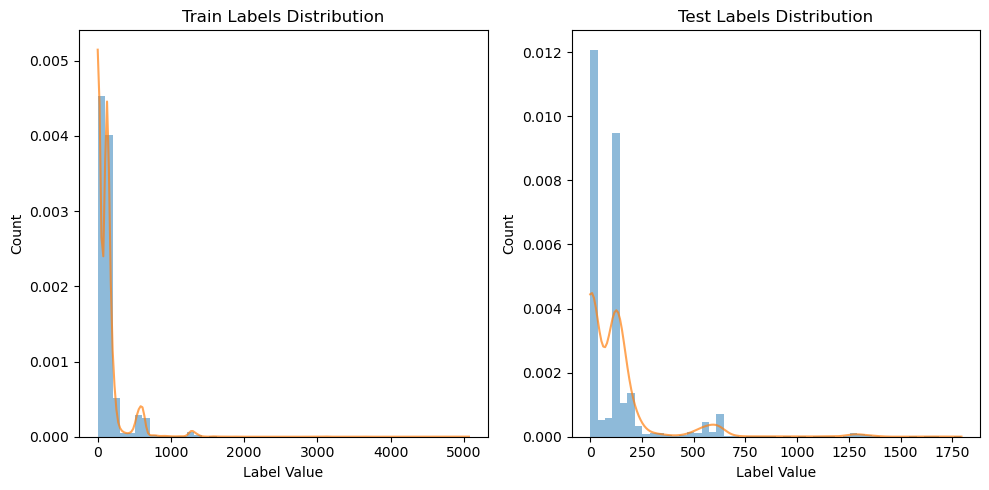

Train Labels Distribution(TOC):
Count: 15843
Mean: 0.726
Std: 1.122
Min: 0.000
Max: 20.200

Test Labels Distribution(TOC):
Count: 5282
Mean: 0.720
Std: 1.119
Min: 0.000
Max: 22.300
Number of zeros in train labels: 9
Number of zeros in test labels: 2


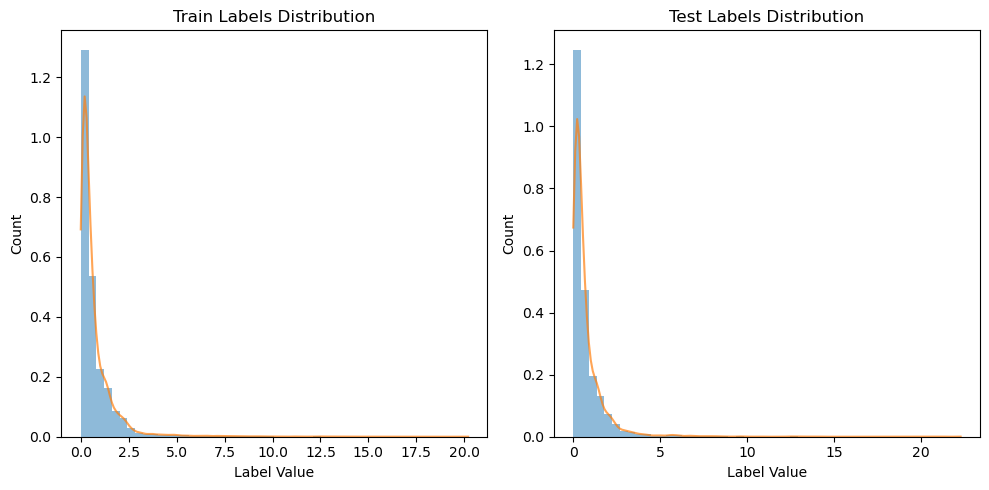

torch.Size([9855, 110])
torch.Size([9855])
1
MTLNN(
  (encoder): Sequential(
    (encoder_linear_0): Linear(in_features=110, out_features=512, bias=True)
    (encoder_relu_0): ReLU()
    (encoder_dropout_0): Dropout(p=0.2, inplace=False)
    (encoder_linear_1): Linear(in_features=512, out_features=512, bias=True)
    (encoder_relu_1): ReLU()
    (encoder_dropout_1): Dropout(p=0.2, inplace=False)
    (encoder_linear_2): Linear(in_features=512, out_features=512, bias=True)
    (encoder_relu_2): ReLU()
    (encoder_dropout_2): Dropout(p=0.2, inplace=False)
    (encoder_linear_3): Linear(in_features=512, out_features=512, bias=True)
    (encoder_relu_3): ReLU()
    (encoder_dropout_3): Dropout(p=0.2, inplace=False)
  )
  (task_sedimentation_rates_head): Sequential(
    (0): Linear(in_features=512, out_features=1, bias=True)
  )
  (task_toc_head): Sequential(
    (0): Linear(in_features=512, out_features=1, bias=True)
  )
)
2000
[512, 512, 512, 512]
4
Task 1 : Sedimentation rates
Task 2 : T

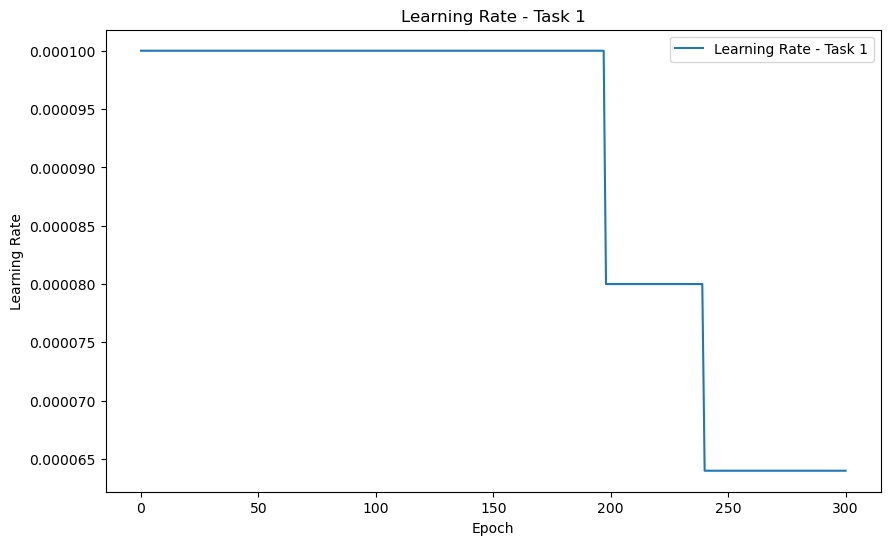

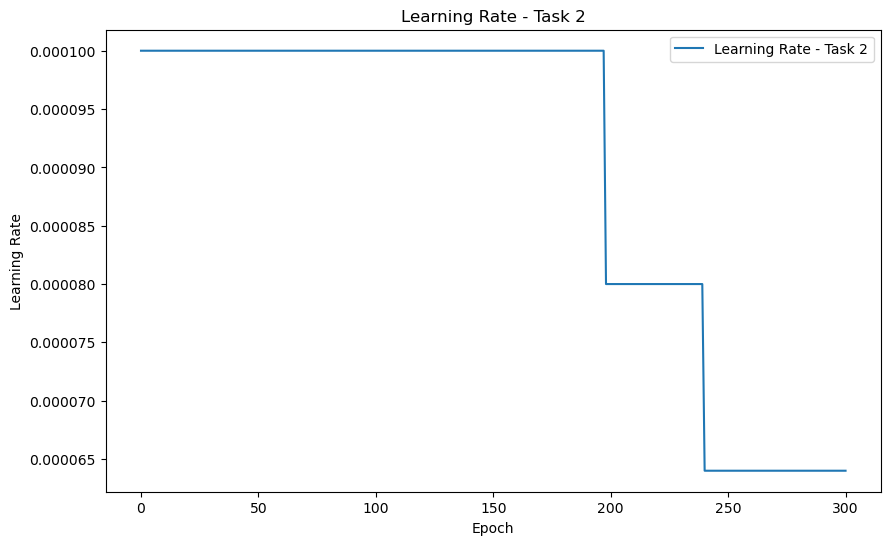

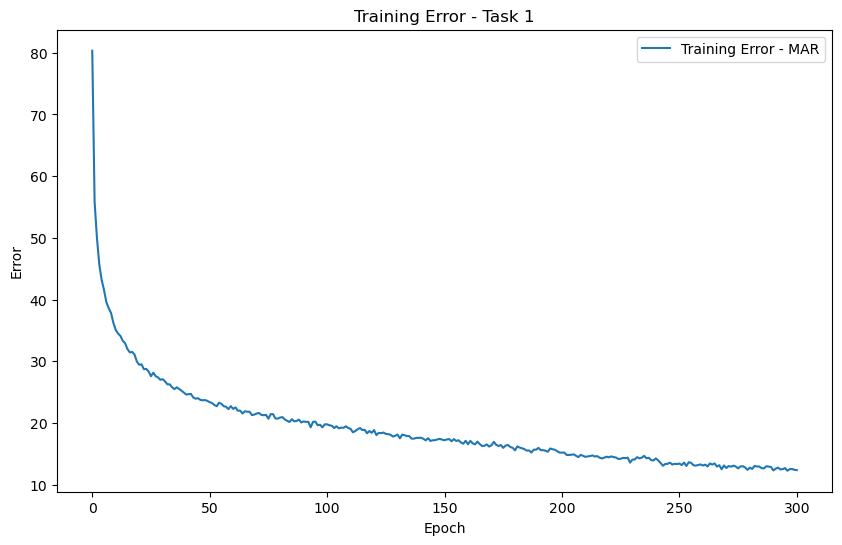

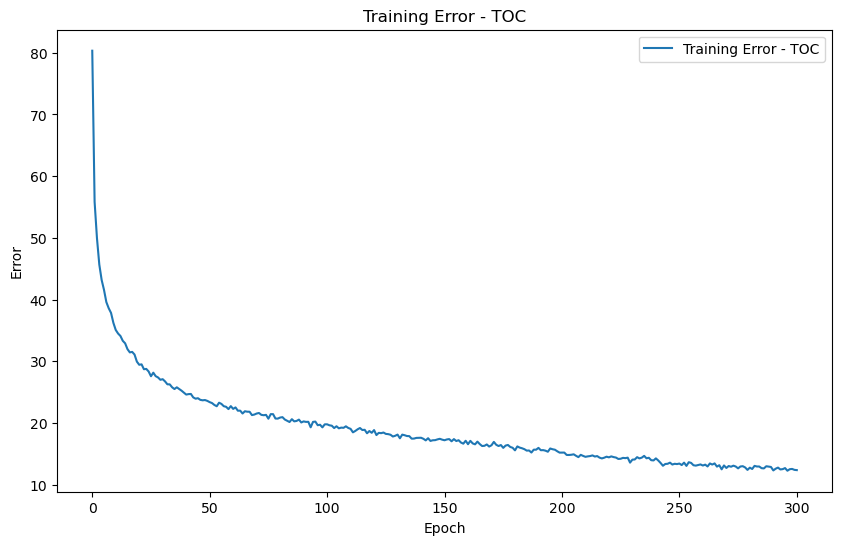

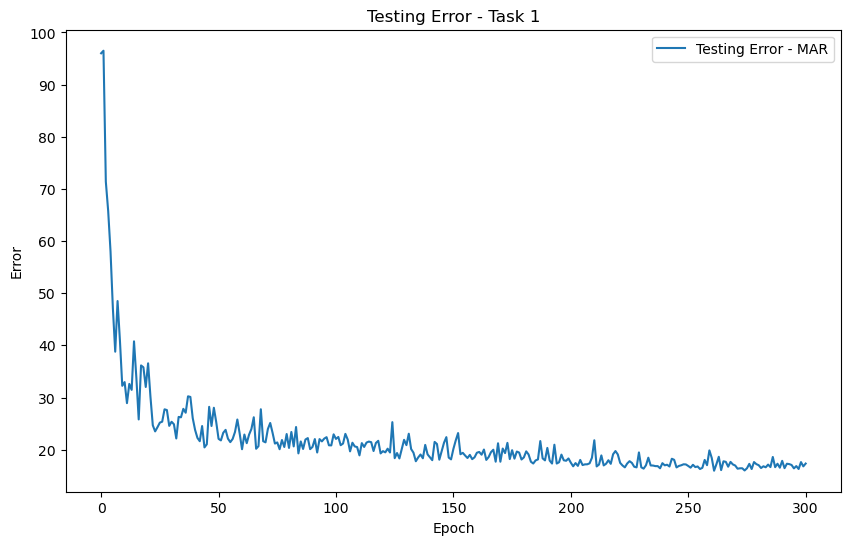

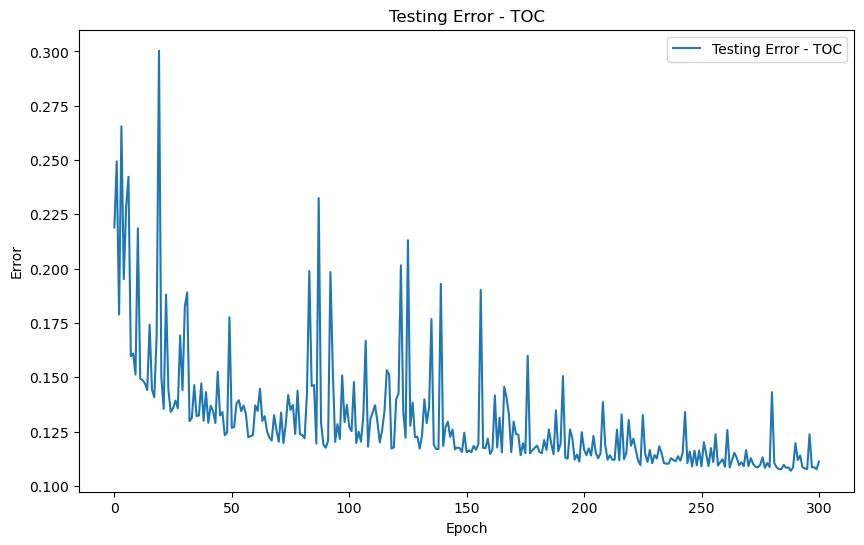

To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).


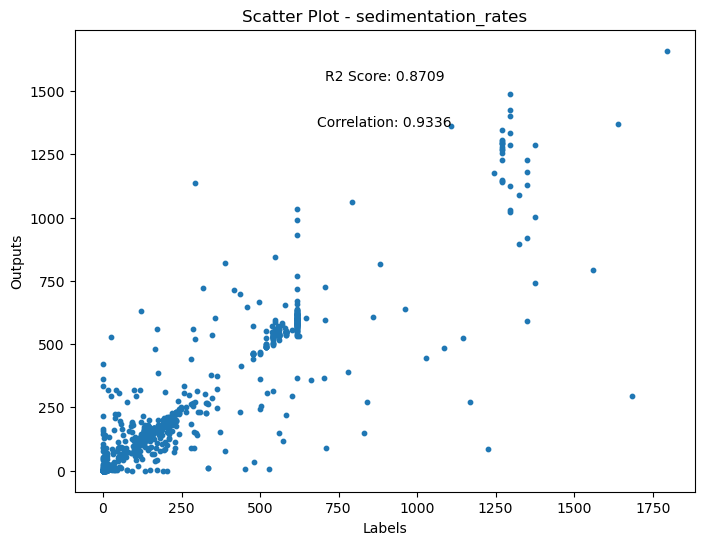

To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).


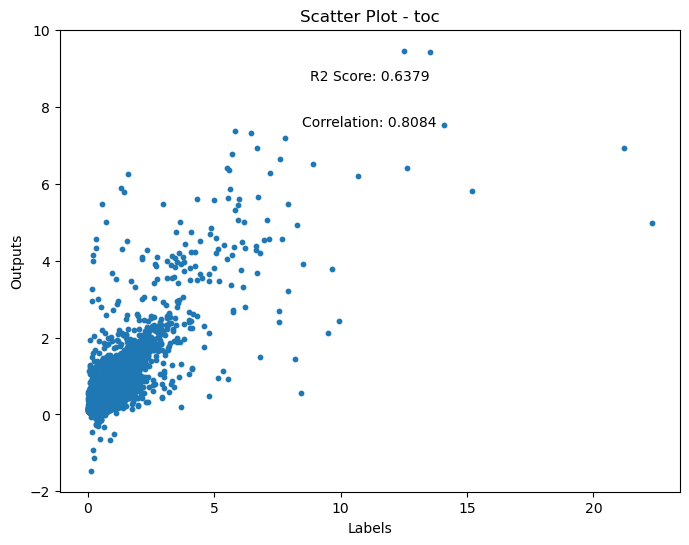

To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).



=== Training Set Results ===

Task: sedimentation_rates
MAE: 10.0260
MSE: 4317.3467
Correlation Coefficient: 0.9509
R² Score: 0.9026

Task: toc
MAE: 0.2692
MSE: 0.3712
Correlation Coefficient: 0.8498
R² Score: 0.7050

=== Test Set Results ===


To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).



Task: sedimentation_rates
MAE: 17.1036
MSE: 5119.3594
Correlation Coefficient: 0.9336
R² Score: 0.8709

Task: toc
MAE: 0.2874
MSE: 0.4533
Correlation Coefficient: 0.8084
R² Score: 0.6379


To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).


In [4]:
# %%
layer_widths_all = [[512]*4]#, [512]*4, [512]*5, [512]*6, [512]*7, [512]*8, [128]*3, [128]*4, [128]*5, [128]*6, [128]*7, [128]*8, [64]*3, [64]*4, [64]*5, [64]*6, [64]*7, [64]*8]
num_shared_layers_all = [4]#, 2, 3, 4, 5, 6, 7, 8]
count_mtl = 0
for layer_width in layer_widths_all:
    for num_shared_layers in num_shared_layers_all:
        print(f"Training MTL model {count_mtl} with layer_widths={layer_width} and num_shared_layers={num_shared_layers}")
        count_mtl = count_mtl + 1
        layer_widths = layer_width
        num_shared_layers = num_shared_layers
        if num_shared_layers > len(layer_widths):
            continue

        print(sedrate_train_features.shape)
        sedrate_train_features = torch.tensor(sedrate_train_features, dtype=torch.float32)
        sedrate_train_labels = torch.tensor(sedrate_train_labels, dtype=torch.float32)
        sedrate_test_features = torch.tensor(sedrate_test_features, dtype=torch.float32)
        sedrate_test_labels = torch.tensor(sedrate_test_labels, dtype=torch.float32)

        toc_train_features = torch.tensor(toc_train_features, dtype=torch.float32)
        toc_train_labels = torch.tensor(toc_train_labels, dtype=torch.float32)
        toc_test_features = torch.tensor(toc_test_features, dtype=torch.float32)
        toc_test_labels = torch.tensor(toc_test_labels, dtype=torch.float32)
        # Create TensorDatasets
        sedrate_train_dataset = TensorDataset(sedrate_train_features, sedrate_train_labels)
        sedrate_test_dataset = TensorDataset(sedrate_test_features, sedrate_test_labels)
        toc_train_dataset = TensorDataset(toc_train_features, toc_train_labels)
        toc_test_dataset = TensorDataset(toc_test_features, toc_test_labels)
        

        # Create DataLoaders
        batch_size = 32
        train_dataloaders = {
            'sedimentation_rates': DataLoader(sedrate_train_dataset, batch_size=batch_size, shuffle=True),
            'toc': DataLoader(toc_train_dataset, batch_size=batch_size, shuffle=True)
        }
        test_dataloaders = {
            'sedimentation_rates': DataLoader(sedrate_test_dataset, batch_size=batch_size, shuffle=False),
            'toc': DataLoader(toc_test_dataset, batch_size=batch_size, shuffle=False)
        }

        # Now you can use train_dataloaders and test_dataloaders in your training loop, e.g.:
        # for features, labels in train_dataloaders['sedimentation_rates']:
        #     # training step here

        # %%
        print("Train Labels Distribution(Sedimentation Rates):")
        print(f"Count: {len(sedrate_train_labels)}")
        print(f"Mean: {sedrate_train_labels.mean():.3f}")
        print(f"Std: {sedrate_train_labels.std():.3f}")
        print(f"Min: {sedrate_train_labels.min():.3f}")
        print(f"Max: {sedrate_train_labels.max():.3f}")
        print("\nTest Labels Distribution(Sedimentation Rates):")
        print(f"Count: {len(sedrate_test_labels)}")
        print(f"Mean: {sedrate_test_labels.mean():.3f}") 
        print(f"Std: {sedrate_test_labels.std():.3f}")
        print(f"Min: {sedrate_test_labels.min():.3f}")
        print(f"Max: {sedrate_test_labels.max():.3f}")

        # Plot histograms
        import matplotlib.pyplot as plt

        # Count number of zeros in train and test labels
        train_zeros = (sedrate_train_labels == 0).sum()
        test_zeros = (sedrate_test_labels == 0).sum()
        print(f"Number of zeros in train labels: {train_zeros}")
        print(f"Number of zeros in test labels: {test_zeros}")

        plt.figure(figsize=(10,5))
        from scipy.stats import gaussian_kde
        plt.subplot(1,2,1)
        plt.hist(sedrate_train_labels, bins=50, alpha=0.5, density=True)
        kde = gaussian_kde(sedrate_train_labels)
        x_range = np.linspace(min(sedrate_train_labels), max(sedrate_train_labels), 200)
        plt.plot(x_range, kde(x_range), alpha=0.7)
        plt.title('Train Labels Distribution')
        plt.xlabel('Label Value')
        plt.ylabel('Count')

        plt.subplot(1,2,2)
        plt.hist(sedrate_test_labels, bins=50, alpha=0.5, density=True)
        kde = gaussian_kde(sedrate_test_labels)
        x_range = np.linspace(min(sedrate_test_labels), max(sedrate_test_labels), 200)
        plt.plot(x_range, kde(x_range), alpha=0.7)
        plt.title('Test Labels Distribution')
        plt.xlabel('Label Value')
        plt.ylabel('Count')

        plt.tight_layout()
        plt.show()


        # %%
        print("Train Labels Distribution(TOC):")
        print(f"Count: {len(toc_train_labels)}")
        print(f"Mean: {toc_train_labels.mean():.3f}")
        print(f"Std: {toc_train_labels.std():.3f}")
        print(f"Min: {toc_train_labels.min():.3f}")
        print(f"Max: {toc_train_labels.max():.3f}")
        print("\nTest Labels Distribution(TOC):")
        print(f"Count: {len(toc_test_labels)}")
        print(f"Mean: {toc_test_labels.mean():.3f}") 
        print(f"Std: {toc_test_labels.std():.3f}")
        print(f"Min: {toc_test_labels.min():.3f}")
        print(f"Max: {toc_test_labels.max():.3f}")

        # Plot histograms
        import matplotlib.pyplot as plt

        # Count number of zeros in train and test labels
        train_zeros = (toc_train_labels == 0).sum()
        test_zeros = (toc_test_labels == 0).sum()
        print(f"Number of zeros in train labels: {train_zeros}")
        print(f"Number of zeros in test labels: {test_zeros}")

        plt.figure(figsize=(10,5))
        from scipy.stats import gaussian_kde
        plt.subplot(1,2,1)
        plt.hist(toc_train_labels, bins=50, alpha=0.5, density=True)
        kde = gaussian_kde(toc_train_labels)
        x_range = np.linspace(min(toc_train_labels), max(toc_train_labels), 200)
        plt.plot(x_range, kde(x_range), alpha=0.7)
        plt.title('Train Labels Distribution')
        plt.xlabel('Label Value')
        plt.ylabel('Count')

        plt.subplot(1,2,2)
        plt.hist(toc_test_labels, bins=50, alpha=0.5, density=True)
        kde = gaussian_kde(toc_test_labels)
        x_range = np.linspace(min(toc_test_labels), max(toc_test_labels), 200)
        plt.plot(x_range, kde(x_range), alpha=0.7)
        plt.title('Test Labels Distribution')
        plt.xlabel('Label Value')
        plt.ylabel('Count')

        plt.tight_layout()
        plt.show()


        # %%
        toc_test_features.shape

        # %%
        """
        # Convert all arrays to PyTorch tensors (if not already)
        toc_features_train = torch.tensor(toc_features_train, dtype=torch.float32)
        toc_labels_train = torch.tensor(toc_labels_train, dtype=torch.float32)

        sedrate_features_train = torch.tensor(sedrate_features_train, dtype=torch.float32)
        sedrate_labels_train = torch.tensor(sedrate_labels_train, dtype=torch.float32)

        toc_features_test = torch.tensor(toc_features_test, dtype=torch.float32)
        toc_labels_test = torch.tensor(toc_labels_test, dtype=torch.float32)

        sedrate_features_test = torch.tensor(sedrate_features_test, dtype=torch.float32)
        sedrate_labels_test = torch.tensor(sedrate_labels_test, dtype=torch.float32)

        # Now wrap into DataLoaders
        train_data = {
            'toc': DataLoader(TensorDataset(toc_features_train, toc_labels_train), batch_size=64, shuffle=True),
            'sedimentation_rates': DataLoader(TensorDataset(sedrate_features_train, sedrate_labels_train), batch_size=64, shuffle=True)
        }

        test_data = {
            'toc': DataLoader(TensorDataset(toc_features_test, toc_labels_test), batch_size=64, shuffle=False),
            'sedimentation_rates': DataLoader(TensorDataset(sedrate_features_test, sedrate_labels_test), batch_size=64, shuffle=False)
        }
        """



        # %%
        #test_data['sedimentation_rates'][0][1].shape

        # %%
        features_list = []
        labels_list = []
        for task in train_dataloaders:
            if task == "toc":
                continue
            for features, labels in train_dataloaders[task]:
                features_list.append(features)
                labels_list.append(labels)


        features = torch.cat(features_list, dim=0)
        labels = torch.cat(labels_list, dim=0)

        print(features.shape)
        print(labels.shape)

        # %%
        learning_rates = []  # List to store learning rates
        train_errors_task1 = []  # List to store training errors for task 1
        train_errors_task2 = []  # List to store training errors for task 2
        test_errors_task1 = []  # List to store testing errors for task 1
        test_errors_task2 = []  # List to store testing errors for task 2

        train_step = 2
        #"""
        num_epochs = 2000
        model = buildDNN(layer_widths, sedrate_features, num_shared_layers)
        print(count_mtl)
        print(model)
        print(num_epochs)
        print(layer_widths)
        print(num_shared_layers)
        #for param in model.decoder.parameters():
        #    param.requires_grad = False    
            #for key in loss_fn:
            #    loss_fn[key] = loss_fn[key].cuda()
        #"""
        if torch.cuda.is_available():
            model = model.cuda()    
            loss_fn = loss_fn.cuda()

        print("Task 1 : Sedimentation rates")
        print("Task 2 : TOC")

        # Training loop
        training_losses, learning_rate, evaluation_losses =  train_model(model, loss_fn, train_dataloaders, test_dataloaders, train_step=2, num_epochs=num_epochs)
            

        # %%
        from sklearn.metrics import r2_score        
        # Plotting the learning rate for each task
        plt.figure(figsize=(10, 6))
        plt.plot(learning_rate, label='Learning Rate - Task 1')
        plt.xlabel('Epoch')
        plt.ylabel('Learning Rate')
        plt.title('Learning Rate - Task 1')
        plt.legend()
        plt.show()

        plt.figure(figsize=(10, 6))
        plt.plot(learning_rate, label='Learning Rate - Task 2')
        plt.xlabel('Epoch')
        plt.ylabel('Learning Rate')
        plt.title('Learning Rate - Task 2')
        plt.legend()
        plt.show()

        # Plotting the train errors for each task
        plt.figure(figsize=(10, 6))
        training_losses_mar = [training_loss['sedimentation_rates'] for training_loss in training_losses]
        plt.plot(training_losses_mar, label='Training Error - MAR')
        plt.xlabel('Epoch')
        plt.ylabel('Error')
        plt.title('Training Error - Task 1')
        plt.legend()
        plt.show()

        plt.figure(figsize=(10, 6))
        training_losses_toc = [training_loss['sedimentation_rates'] for training_loss in training_losses]
        plt.plot(training_losses_toc, label='Training Error - TOC')
        plt.xlabel('Epoch')
        plt.ylabel('Error')
        plt.title('Training Error - TOC')
        plt.legend()
        plt.show()

        # Plotting the test errors for each task
        plt.figure(figsize=(10, 6))
        testing_losses_mar = [testing_loss['sedimentation_rates'] for testing_loss in evaluation_losses]
        plt.plot(testing_losses_mar, label='Testing Error - MAR')
        plt.xlabel('Epoch')
        plt.ylabel('Error')
        plt.title('Testing Error - Task 1')
        plt.legend()
        plt.show()

        plt.figure(figsize=(10, 6))
        testing_losses_toc = [testing_loss['toc'] for testing_loss in evaluation_losses]
        plt.plot(testing_losses_toc, label='Testing Error - TOC')
        plt.xlabel('Epoch')
        plt.ylabel('Error')
        plt.title('Testing Error - TOC')
        plt.legend()
        plt.show()

        for task in test_dataloaders:
            features_list = []
            labels_list = []
            for features, labels in test_dataloaders[task]:
                features = torch.tensor(features).to(device)
                features = features.to(dtype=torch.double)
                labels = torch.tensor(labels).to(device)
                labels = labels.to(dtype=torch.double)
                features_list.append(features)
                labels_list.append(labels)
            # After the loop, concatenate all features and labels
            features = torch.cat(features_list, dim=0)
            labels = torch.cat(labels_list, dim=0)
            decoded, outputs = model(features, task)
            labels = labels.reshape(-1)  # Reshape labels to match outputs
            labels = labels.cpu().detach().numpy()

            if task == "sedimentation_rates":
                outputs = outputs.cpu().detach().numpy().reshape(-1)  # Reshape outputs to match labels
            else:
                outputs = outputs.cpu().detach().numpy().reshape(-1)  # Reshape outputs to match labels
            #labels = labels.cpu().detach().numpy().reshape(-1)
            mae = mean_absolute_error(labels, outputs)
            mse = mean_squared_error(labels, outputs)
            rmse = np.sqrt(mean_squared_error(labels, outputs))


            # Calculate R2 score and correlation coefficient
            r2 = r2_score(labels, outputs)

            correlation = np.corrcoef(labels, outputs)[0, 1]

            # Create scatter plot of labels vs outputs
            plt.figure(figsize=(8, 6))
            plt.scatter(labels, outputs, s=10)
            plt.xlabel("Labels")
            plt.ylabel("Outputs")
            plt.title(f"Scatter Plot - {task}")
            plt.text(0.5, 0.9, f"R2 Score: {r2:.4f}", ha='center', va='center', transform=plt.gca().transAxes)
            plt.text(0.5, 0.8, f"Correlation: {correlation:.4f}", ha='center', va='center', transform=plt.gca().transAxes)
            plt.show()


        # %%

        # Evaluate both training and test results
        print("\n=== Training Set Results ===")
        for task in train_dataloaders:
            mae, mse, corr, r2 = evaluate_model(model, train_dataloaders[task], task, device)
            print(f"\nTask: {task}")
            print(f"MAE: {mae:.4f}")
            print(f"MSE: {mse:.4f}")
            print(f"Correlation Coefficient: {corr:.4f}")
            print(f"R² Score: {r2:.4f}")

        print("\n=== Test Set Results ===")
        for task in test_dataloaders:
            mae, mse, corr, r2 = evaluate_model(model, test_dataloaders[task], task, device)
            print(f"\nTask: {task}")
            print(f"MAE: {mae:.4f}")
            print(f"MSE: {mse:.4f}")
            print(f"Correlation Coefficient: {corr:.4f}")
            print(f"R² Score: {r2:.4f}")

        # %%
        import torch
        from pathlib import Path
        import pickle
        import numpy as np
        from matplotlib import pyplot as plt
        #from sklearn.model_selection import StratifiedKFold, KFold
        #from sklearn.model_selection import train_test_split
        import os
        import gc

In [5]:
def plot_predictions(y_train, train_preds, y_test, test_preds, model_name, n_estimators, save_path=None):
    """
    Plot a single 2D histogram (density plot) of all predictions and metrics.
    Only a single figure is created and returned. There are NOT two subplots.
    """
    # Calculate metrics
    train_mae = mean_absolute_error(y_train, train_preds)
    test_mae = mean_absolute_error(y_test, test_preds)
    train_corr = np.corrcoef(y_train, train_preds)[0, 1]
    test_corr = np.corrcoef(y_test, test_preds)[0, 1]

    # Calculate R² for additional information
    from sklearn.metrics import r2_score
    train_r2 = r2_score(y_train, train_preds)
    test_r2 = r2_score(y_test, test_preds)

    # Combine train and test for density plot
    all_true = np.concatenate([y_train, y_test])
    all_pred = np.concatenate([train_preds, test_preds])

    # Find min and max for axis and binning
    min_lim = min(all_true.min(), all_pred.min())
    max_lim = max(all_true.max(), all_pred.max())

    # Clamp display axis at 1500 as maximum
    min_display = min_lim
    max_display = min(1500, max_lim)

    # Figure size for one subplot (the only plot!)
    fig, ax = plt.subplots(figsize=(4.5, 4.5))

    # Use 2D histogram for density, limiting counts per bin to max 15
    counts, xedges, yedges, im = ax.hist2d(
        all_true, all_pred,
        bins=100,
        range=[[min_display, max_display], [min_display, max_display]],
        cmap='viridis',
        cmin=0, vmax=15
    )
    # Set up colorbar for the single plot
    cbar = plt.colorbar(im, ax=ax, pad=0.02, shrink=0.75, aspect=20)
    cbar.set_label('Counts', fontsize=10, fontweight='bold', labelpad=5)
    cbar.ax.tick_params(labelsize=8)
    cbar_ticks = np.arange(0, 16, 3)
    if cbar_ticks[-1] != 15:
        cbar_ticks = np.append(cbar_ticks, 15)
    cbar.set_ticks(cbar_ticks)
    ticklabels = [f"{int(t)}" for t in cbar_ticks]
    if len(ticklabels) > 0:
        ticklabels[-1] = ">15"
    cbar.set_ticklabels(ticklabels)

    # Grid values and aspect for single plot
    grid_values = [300, 600, 900, 1200, 1500]
    ax.set_xlim(min_display, max_display)
    ax.set_ylim(min_display, max_display)
    ax.set_aspect('equal', adjustable='box')
    ax.set_xticks(grid_values)
    ax.set_yticks(grid_values)
    ax.tick_params(axis='both', labelsize=10)

    # 1:1 reference line
    ax.plot([min_display, max_display], [min_display, max_display], 'k--', lw=2, alpha=0.8)

    # Axis labels and plot title
    ax.set_xlabel('True Values (g cm⁻² ka⁻¹)', fontsize=12, fontweight='bold')
    ax.set_ylabel('Predicted Values (g cm⁻² ka⁻¹)', fontsize=12, fontweight='bold')

    # Place the statistics in a textbox
    textstr = (
        f"Train: MAE={train_mae:.2f}, R²={train_r2:.3f}, CC={train_corr:.3f}\n"
        f"Test:  MAE={test_mae:.2f}, R²={test_r2:.3f}, CC={test_corr:.3f}"
    )
    ax.text(0.05, 0.98, textstr, transform=ax.transAxes, fontsize=8,
            bbox=dict(facecolor='white', alpha=0.85, edgecolor='black', linewidth=1.0, boxstyle='round,pad=0.4'),
            ha='left', va='top', fontweight='bold')

    ax.grid(True, alpha=0.3, linestyle='--', linewidth=0.8)
    plt.tight_layout(pad=0.5)

    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight', facecolor='white', edgecolor='none')
        pdf_path = str(save_path).replace('.png', '.pdf')
        plt.savefig(pdf_path, dpi=300, bbox_inches='tight', facecolor='white', edgecolor='none')
        print(f"Figure saved to {save_path} and {pdf_path}")

    plt.show()
    return fig


In [6]:
def collect_predictions(model, dataloader, task, device):
    model.eval()
    features_list, labels_list, preds_list = [], [], []

    with torch.no_grad():
        for features, labels in dataloader:
            features = torch.tensor(features, dtype=torch.double).to(device)
            labels = torch.tensor(labels, dtype=torch.double).to(device)

            _, outputs = model(features, task)

            features_list.append(features)
            labels_list.append(labels)
            preds_list.append(outputs)

    labels = torch.cat(labels_list).reshape(-1).cpu().numpy()
    preds = torch.cat(preds_list).reshape(-1).cpu().numpy()

    return labels, preds

To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).


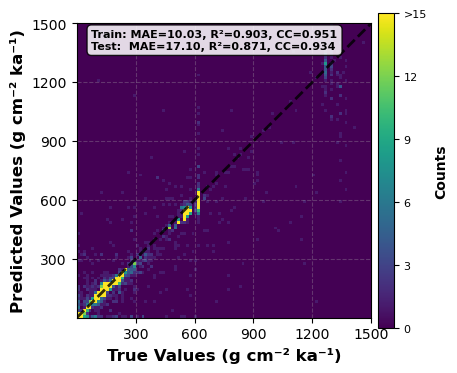

To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).


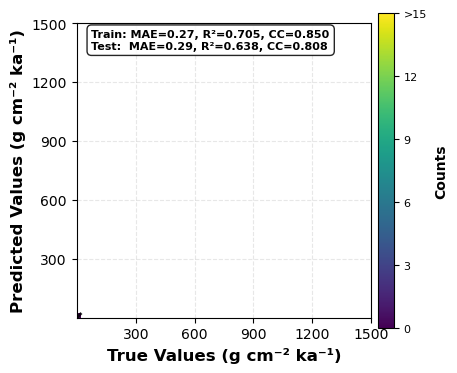

In [7]:
for task in test_dataloaders:

    # Collect TRAIN predictions
    y_train, train_preds = collect_predictions(
        model,
        train_dataloaders[task],
        task,
        device
    )

    # Collect TEST predictions
    y_test, test_preds = collect_predictions(
        model,
        test_dataloaders[task],
        task,
        device
    )

    # Plot using your density-based function
    plot_predictions(
        y_train=y_train,
        train_preds=train_preds,
        y_test=y_test,
        test_preds=test_preds,
        model_name=f"MTL Model – {task}",
        n_estimators=0  # dummy value if not tree-based
    )

cuda:0
prediction 1 done!
prediction 2 done!
prediction 3 done!
prediction 4 done!
prediction 5 done!
prediction 6 done!
prediction 7 done!
prediction 8 done!
prediction 9 done!
prediction 10 done!
prediction 11 done!
prediction 12 done!
prediction 13 done!
prediction 14 done!
prediction 15 done!
prediction 16 done!
prediction 17 done!
prediction 18 done!
prediction 19 done!
prediction 20 done!
prediction 21 done!
prediction 22 done!
prediction 23 done!
prediction 24 done!
prediction 25 done!
prediction 26 done!
prediction 27 done!
prediction 28 done!
prediction 29 done!
prediction 30 done!
prediction 31 done!
prediction 32 done!
prediction 33 done!
prediction 34 done!
prediction 35 done!
prediction 36 done!
prediction 37 done!
prediction 38 done!
prediction 39 done!
prediction 40 done!
prediction 41 done!
prediction 42 done!
prediction 43 done!
prediction 44 done!
prediction 45 done!
prediction 46 done!
prediction 47 done!
prediction 48 done!
prediction 49 done!
prediction 50 done!
pr

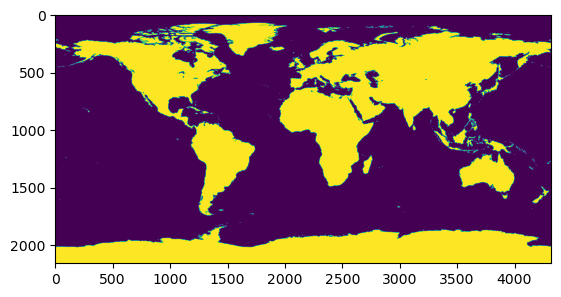

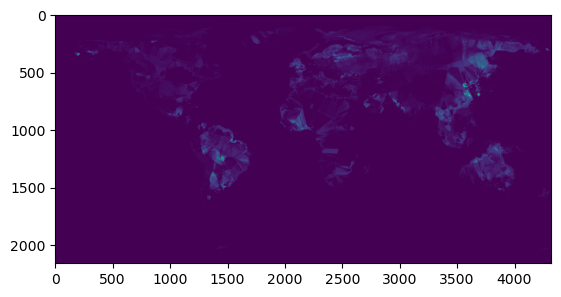

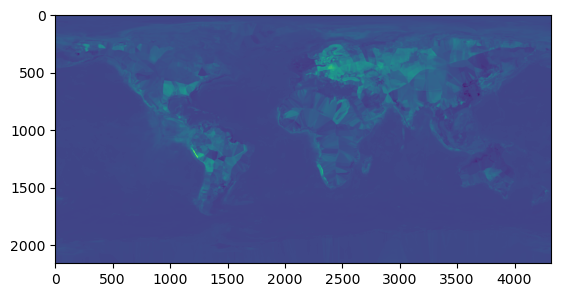

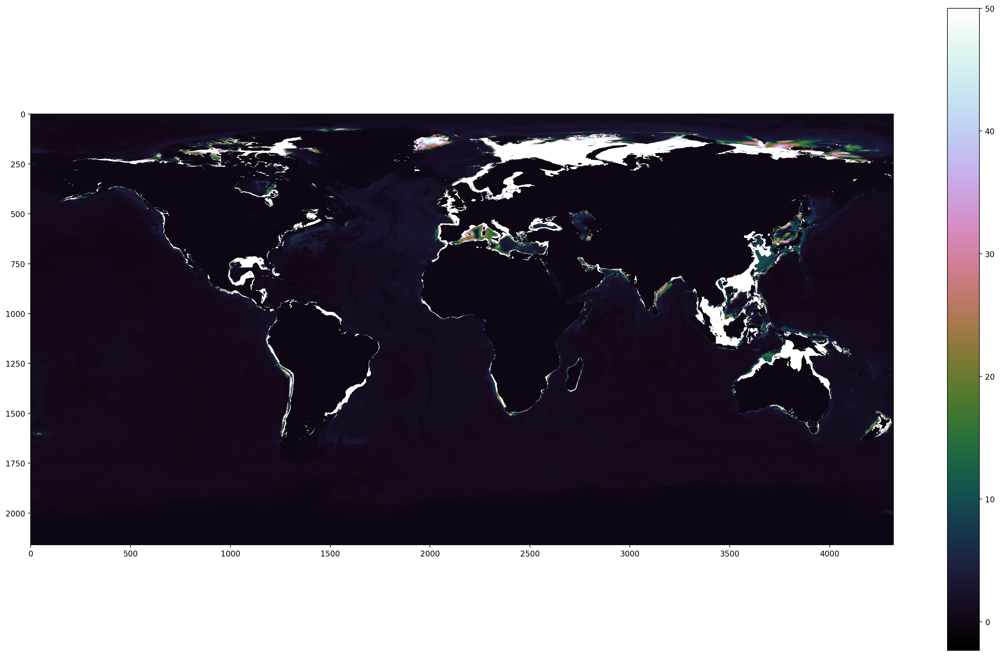

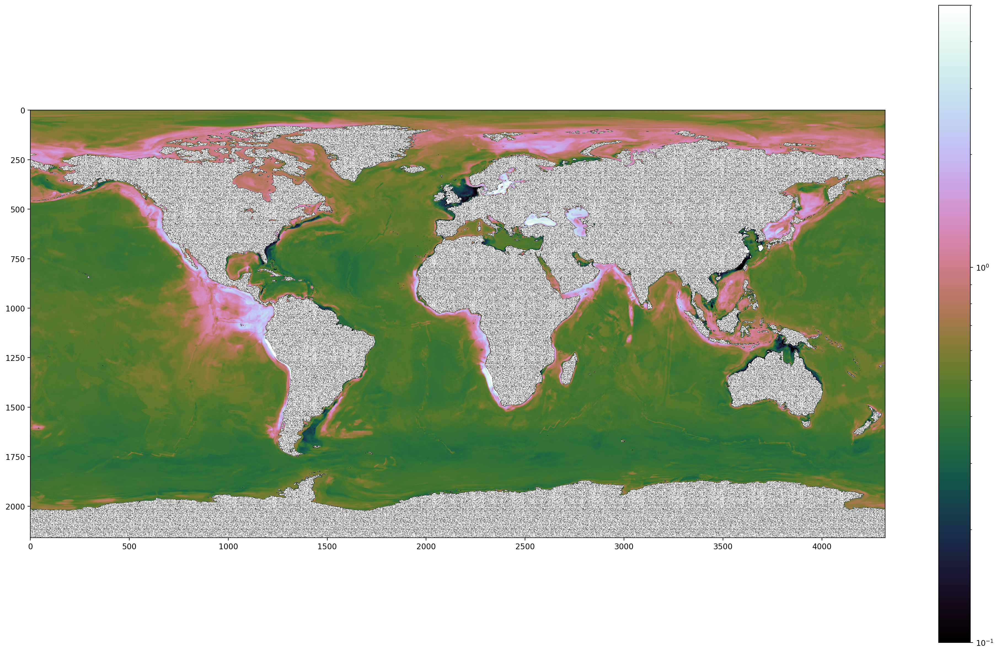

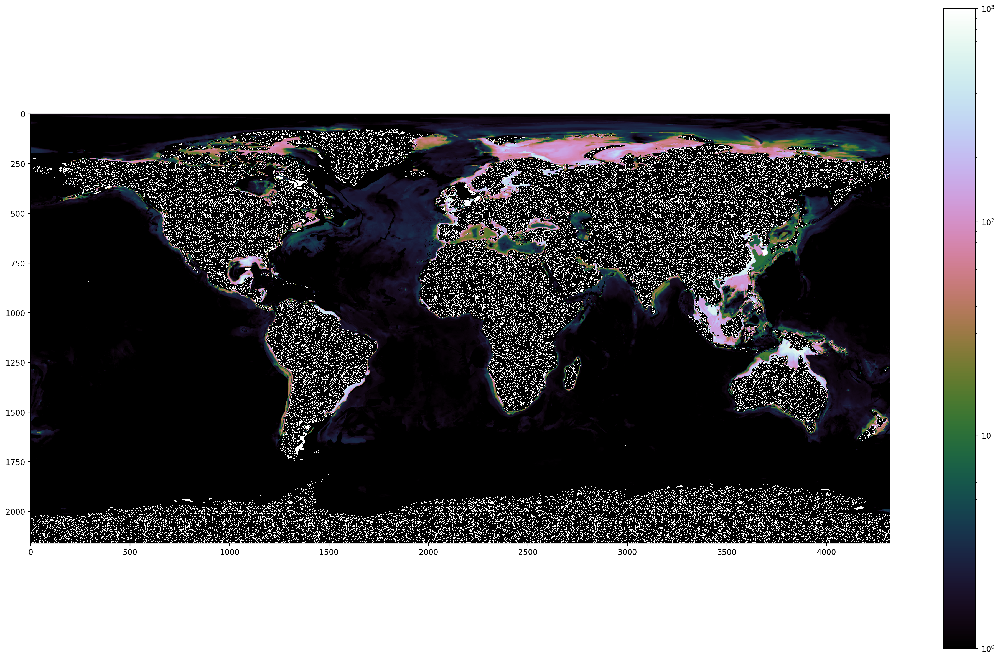

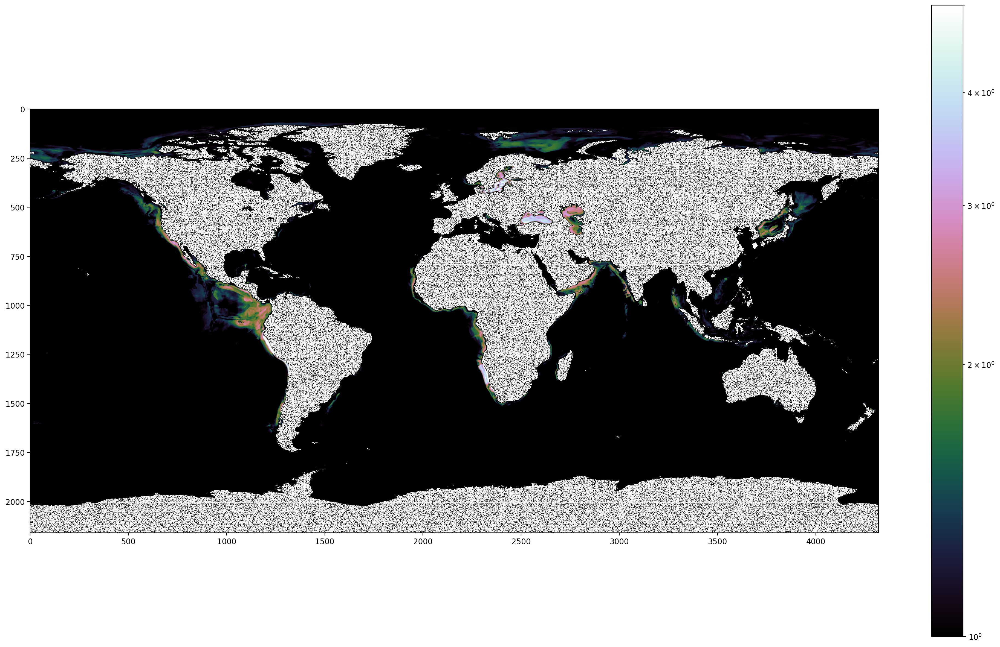

In [8]:
#os.chdir("/gxfs_work1/cau/sunms498/work/david/NN4SedRatePred/models/MLP/SedRate_MAR/models_torch/")


from os import walk  
feature_path = Path(Path() / "/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/interim/inputfeatures/SedTOCFeaturesnoNAN_MAR_DO_men/")
X_mean = np.load(Path(feature_path / "features_mean.npy")).astype(float)
X_std = np.load(Path(feature_path / "features_std.npy")).astype(float)

#dataset_path = Path(Path().resolve().parents[2] / "Data" / "restrepoKNNsTOC" / "WorldFeaturesAll")#ChlorWorldFeatures
dataset_path = Path("/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/interim/worldfeatures/WorldFeaturesAllnoNaN_SedTOC_predict_men/")
files = []

for (dirpath, dirnames, filenames) in walk(dataset_path):
    files.extend(filenames)
    break

files.sort()


features = np.load(Path(dataset_path / files[0]))

#model = FEA(layer_width)
#model.load_state_dict(torch.load("/gxfs_work1/cau/sunms498/work/toc-neural-nets/SelectFeaturesRun/FEAmodel_test0_75.pth"))

model.eval()
#enable_dropout(model) #for mc dropout

chunk_shape = [6,4320] #360 chunks

np.random.seed(42)
torch.manual_seed(42)
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu') #'cuda:0' if torch.cuda.is_available() else 
#print(physical_devices)
model.to(device)
print(device)
model.double()

first_run = True
ii = 0

# %%
task_ids = ["sedimentation_rates", "toc"]

features = np.load(Path(dataset_path / files[0]))

chunk_shape = [6,4320] #360 chunks


first_run = True
ii = 0

for count, file in enumerate(files):

    features = np.load(Path(dataset_path / file))
    features = np.divide((features - X_mean), X_std)

    features = torch.tensor(features)
    features = features.to(device)


    decoded, predictions_sedrate = model(features, task_id = "sedimentation_rates")
    predictions_sedrate = predictions_sedrate.cpu().detach().numpy()
    predictions_sedrate = predictions_sedrate.reshape(chunk_shape,  order = 'C')


    decoded, predictions_toc = model(features, task_id = "toc")
    predictions_toc = predictions_toc.cpu().detach().numpy()
    predictions_toc = predictions_toc.reshape(chunk_shape,  order = 'C')

    if first_run:
        prediction_map_sedrate = predictions_sedrate
        prediction_map_toc = predictions_toc
        first_run = False
    else:
        prediction_map_sedrate = np.append(prediction_map_sedrate, predictions_sedrate, axis = 0)
        prediction_map_toc = np.append(prediction_map_toc, predictions_toc, axis = 0)

    ii+=1
    print("prediction " + str(ii) + " done!")

    del(features)
    gc.collect()

# land_file = Path(Path().resolve().parents[2] / "Data" / "restrepoKNNsTOC" / "island_map.npy")
# land_map = np.load(land_file)
# land_map[np.isnan(land_map)] = 1
#prediction_map[land_map] = np.nan
#plt.imshow(prediction_map)
# np.save("Sed_regresion_deep_RestrepoFeats_AllVS0.2_nolimit", prediction_map)
#prediction_map = np.load("MAR_prediction_map(log(x+1))RestrepoFeats__AllVS0.2.npy")
# from matplotlib.colors import LogNorm
#plot_TOC = 3
# plot_sed = 100
# 


# %%
land_file = "../../data/raw/island_map.npy"
land_map = np.load(land_file)
land_map[np.isnan(land_map)] = 1
prediction_map_sedrate = np.rot90(np.rot90(np.fliplr(prediction_map_sedrate)))
prediction_map_toc = np.rot90(np.rot90(np.fliplr(prediction_map_toc)))
#land_map = np.rot90(np.rot90(np.fliplr(land_map)))
plt.imshow(land_map)
plt.figure()
plt.imshow(prediction_map_sedrate)
plt.figure()
plt.imshow(prediction_map_toc)


# %%
from matplotlib.colors import LogNorm
prediction_map_sedrate[land_map] = 0
prediction_map_toc[land_map] = 0
plt.figure(figsize=[25,15], dpi=200)
plt.imshow(prediction_map_sedrate,vmax=50, cmap = "cubehelix")
plt.colorbar()
plt.figure(figsize=[25,15], dpi=200)
plt.imshow(prediction_map_toc, norm = LogNorm(vmin = 1e-1, vmax = 5), cmap = "cubehelix")
plt.colorbar()

# %%
from matplotlib.colors import LogNorm
prediction_map_sedrate[land_map] = 0
prediction_map_toc[land_map] = 0
plt.figure(figsize=[25,15], dpi=200)
plt.imshow(prediction_map_sedrate, norm = LogNorm(vmin = 1e0, vmax = 1e3), cmap = "cubehelix")
plt.colorbar()
plt.figure(figsize=[25,15], dpi=200)
plt.imshow(prediction_map_toc, norm = LogNorm(vmin = 1e0, vmax = 5), cmap = "cubehelix")
plt.colorbar()

# %%

In [ ]:
#os.chdir("/gxfs_work1/cau/sunms498/work/david/NN4SedRatePred/models/MLP/SedRate_MAR/models_torch/")
"""
from os import walk  
feature_path = Path(Path() / "/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/interim/inputfeatures/SedTOCFeaturesnoNAN_MAR_DO_men/")
X_mean = np.load(Path(feature_path / "features_mean.npy")).astype(float)
X_std = np.load(Path(feature_path / "features_std.npy")).astype(float)

#dataset_path = Path(Path().resolve().parents[2] / "Data" / "restrepoKNNsTOC" / "WorldFeaturesAll")#ChlorWorldFeatures
dataset_path = Path("/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/interim/worldfeatures/WorldFeaturesAllnoNaN_SedTOC_predict_men/")
files = []

for (dirpath, dirnames, filenames) in walk(dataset_path):
    files.extend(filenames)
    break

files.sort()

features = np.load(Path(dataset_path / files[0]))

#model = FEA(layer_width)
#model.load_state_dict(torch.load("/gxfs_work1/cau/sunms498/work/toc-neural-nets/SelectFeaturesRun/FEAmodel_test0_75.pth"))

model.eval()

def enable_dropout(model):
    for m in model.modules():
        if m.__class__.__name__.startswith('Dropout'):
            m.train()

enable_dropout(model) # Enable dropout for MC Dropout

chunk_shape = [6,4320] #360 chunks

np.random.seed(42)
torch.manual_seed(42)
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
#print(physical_devices)
model.to(device)
print(device)
model.double()

first_run = True
ii = 0

# MC Dropout config
num_samples = 100  # Customize as needed

task_ids = ["sedimentation_rates", "toc"]
chunk_shape = [6,4320]

first_run = True
ii = 0

# Be sure your save directory exists (change as needed)
import os
prediction_sum_save_dir = "/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/output/predictionmaps_SedRate/hyperparameter_optimization/predictions_sum_sedrate_toc"
os.makedirs(prediction_sum_save_dir, exist_ok=True)

for count, file in enumerate(files):

    features = np.load(Path(dataset_path / file))
    features = np.divide((features - X_mean), X_std)
    features = torch.tensor(features)
    features = features.to(device)

    # MC Dropout for both Sed Rate and TOC
    predictions_sum_sedrate = np.zeros((num_samples, chunk_shape[0], chunk_shape[1]))
    predictions_sum_toc = np.zeros((num_samples, chunk_shape[0], chunk_shape[1]))

    with torch.no_grad():
        for i in range(num_samples):
            _, predictions_sedrate = model(features, task_id="sedimentation_rates")
            _, predictions_toc = model(features, task_id="toc")

            predictions_sedrate_np = predictions_sedrate.cpu().detach().numpy().reshape(chunk_shape, order="C")
            predictions_toc_np = predictions_toc.cpu().detach().numpy().reshape(chunk_shape, order="C")

            predictions_sum_sedrate[i] = predictions_sedrate_np
            predictions_sum_toc[i] = predictions_toc_np

    # Save the predictions_sum arrays as .npy files (like in TOC_NN_CS.ipynb)
    save_path_sed = os.path.join(prediction_sum_save_dir, f'predictions_sum_sedrate_{ii}.npy')
    save_path_toc = os.path.join(prediction_sum_save_dir, f'predictions_sum_toc_{ii}.npy')
    np.save(save_path_sed, predictions_sum_sedrate)
    np.save(save_path_toc, predictions_sum_toc)

    predictions_avg_sedrate = np.mean(predictions_sum_sedrate, axis=0)
    predictions_var_sedrate = np.var(predictions_sum_sedrate, axis=0)
    predictions_avg_toc = np.mean(predictions_sum_toc, axis=0)
    predictions_var_toc = np.var(predictions_sum_toc, axis=0)

    if first_run:
        prediction_map_sedrate = predictions_avg_sedrate
        prediction_map_sedrate_var = predictions_var_sedrate
        prediction_map_toc = predictions_avg_toc
        prediction_map_toc_var = predictions_var_toc
        first_run = False
    else:
        prediction_map_sedrate = np.append(prediction_map_sedrate, predictions_avg_sedrate, axis=0)
        prediction_map_sedrate_var = np.append(prediction_map_sedrate_var, predictions_var_sedrate, axis=0)
        prediction_map_toc = np.append(prediction_map_toc, predictions_avg_toc, axis=0)
        prediction_map_toc_var = np.append(prediction_map_toc_var, predictions_var_toc, axis=0)

    ii += 1
    print("prediction " + str(ii) + " done!")

    del(features)
    gc.collect()

# Optionally, the uncertainty maps (prediction_map_sedrate_var, prediction_map_toc_var) can also be saved or visualized

# land_file = Path(Path().resolve().parents[2] / "Data" / "restrepoKNNsTOC" / "island_map.npy")
# land_map = np.load(land_file)
# land_map[np.isnan(land_map)] = 1
#prediction_map[land_map] = np.nan
#plt.imshow(prediction_map)
# np.save("Sed_regresion_deep_RestrepoFeats_AllVS0.2_nolimit", prediction_map)
#prediction_map = np.load("MAR_prediction_map(log(x+1))RestrepoFeats__AllVS0.2.npy")
# from matplotlib.colors import LogNorm
#plot_TOC = 3
# plot_sed = 100
# 


# %%
land_file = "../../data/raw/island_map.npy"
land_map = np.load(land_file)
land_map[np.isnan(land_map)] = 1
prediction_map_sedrate = np.rot90(np.rot90(np.fliplr(prediction_map_sedrate)))
prediction_map_toc = np.rot90(np.rot90(np.fliplr(prediction_map_toc)))
#land_map = np.rot90(np.rot90(np.fliplr(land_map)))
plt.imshow(land_map)
plt.figure()
plt.imshow(prediction_map_sedrate)
plt.figure()
plt.imshow(prediction_map_toc)

# If you want, plot the uncertainty maps as well:
# plt.figure()
# plt.imshow(np.rot90(np.rot90(np.fliplr(prediction_map_sedrate_var))))
# plt.colorbar()
# plt.title("Sedimentation Rate Prediction Variance")
# plt.figure()
# plt.imshow(np.rot90(np.rot90(np.fliplr(prediction_map_toc_var))))
# plt.colorbar()
# plt.title("TOC Prediction Variance")

# %%
from matplotlib.colors import LogNorm
prediction_map_sedrate[land_map] = 0
prediction_map_toc[land_map] = 0
plt.figure(figsize=[25,15], dpi=200)
plt.imshow(prediction_map_sedrate,vmax=50, cmap = "cubehelix")
plt.colorbar()
plt.figure(figsize=[25,15], dpi=200)
plt.imshow(prediction_map_toc, norm = LogNorm(vmin = 1e-1, vmax = 5), cmap = "cubehelix")
plt.colorbar()

# %%
from matplotlib.colors import LogNorm
prediction_map_sedrate[land_map] = 0
prediction_map_toc[land_map] = 0
plt.figure(figsize=[25,15], dpi=200)
plt.imshow(prediction_map_sedrate, norm = LogNorm(vmin = 1e0, vmax = 1e3), cmap = "cubehelix")
plt.colorbar()
plt.figure(figsize=[25,15], dpi=200)
plt.imshow(prediction_map_toc, norm = LogNorm(vmin = 1e0, vmax = 5), cmap = "cubehelix")
plt.colorbar()

# %%
"""

In [ ]:
"""
import os
import numpy as np
prediction_sum_save_dir = "/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/output/predictionmaps_SedRate/hyperparameter_optimization/predictions_sum_sedrate_toc"

# Get a list of files in the directory and sort them
files_in_dir = sorted([f for f in os.listdir(prediction_sum_save_dir) if f.endswith('.npy')], key=lambda x: int(x.split('_')[-1][:-4]))


failed_fits_all = []
i = 0
first_run = True

# Load and concatenate each predictions_sum array along the second axis
for file in files_in_dir:
    file_path = os.path.join(prediction_sum_save_dir, file)
    predictions_sum = np.load(file_path)
    
    if first_run:
        prediction_map_dist = predictions_sum
        first_run = False
    else:
        # Concatenate along the second axis (axis=1)
        prediction_map_dist = np.concatenate((prediction_map_dist, predictions_sum), axis=1)

    i += 1
    print(i)
np.save(Path().resolve().parents[1] / "data" / "output" / "predictionmaps_SedRate" / "prediction_map_dist_entire.npy", prediction_map_dist)
"""

In [8]:
# Save the numpy arrays
np.save('/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/output/predictionmaps_SedRate/hyperparameter_optimization/prediction_map_MAR_entire_MTL_n_test' + '.npy', prediction_map_sedrate)
np.save('/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/output/predictionmaps_SedRate/hyperparameter_optimization/prediction_map_toc_entire_MTL_n_test' + '.npy', prediction_map_toc)

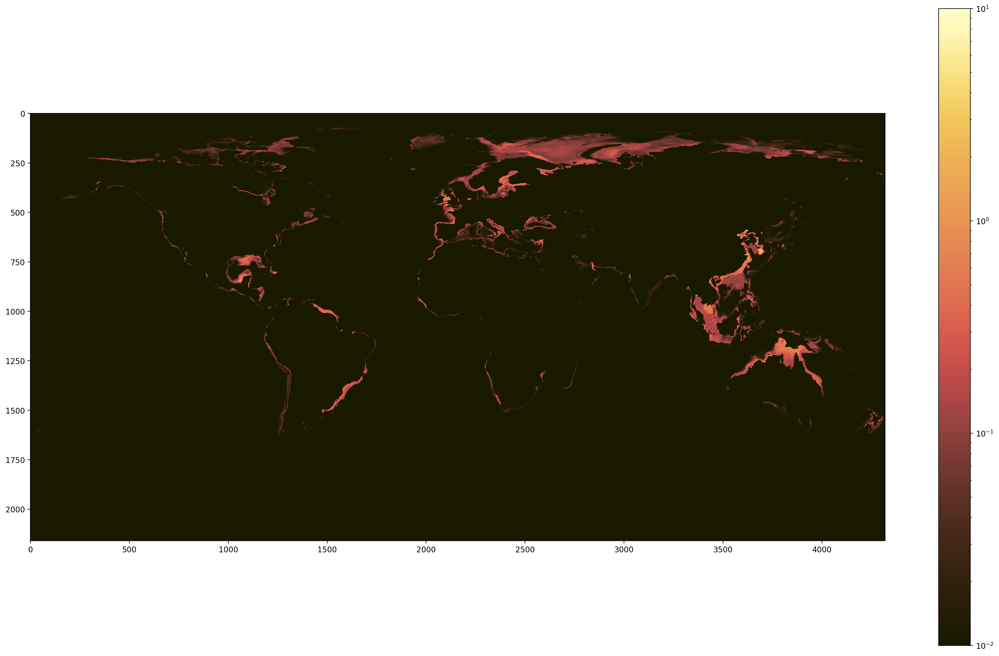

In [8]:
import cmcrameri.cm as cmc
MAR = prediction_map_sedrate
MAR_plot = MAR
small_value = 1e-3  # smaller than vmin=1e-2, but not too small for log scale
MAR_plot = np.where(np.isnan(MAR), np.nan, np.where(MAR <= 0, small_value, MAR))

# Set the color for NaN values to a darker color (e.g., dark gray)


cmap = cmc.lajolla.copy()
cmap.set_bad(color='#888888')  # a little darker gray for NaNs


plt.figure(figsize=[25,15], dpi=200)
plt.imshow(MAR_plot/1e3, norm = LogNorm(vmin = 1e-2, vmax = 1e1), cmap = cmap)#"cubehelix")
plt.colorbar()

In [ ]:
# Load the lat/lon grid and area info using xarray
restrepo_features_path = "/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/raw/features/FeaturesPhrampusLee_TOCSedRate_updated/GL_LATITUDE_DD.5m.nc"
rootgrp = xr.open_dataset(restrepo_features_path, format = 'NETCDF4')
latitudes = rootgrp.variables['lat']
longitudes = rootgrp.variables['lon']
dataset = rootgrp.variables['data']
area = 9.297**2 * np.cos(dataset/180 * np.pi)
area_np = np.array(area) # in km²:  10¹⁰ cm² = 1 km²

# Loop over each .npy file, load as MAR_plot and compute the sediment budget
sediment_budgets = {}

for filename in npy_files:
filepath = os.path.join(npy_dir, filename)
if not os.path.isfile(filepath):
    print(f"File not found: {filepath}")
    continue

MAR_plot = np.load(filepath)
# If needed, handle NaNs or zero/negative values similar to other code blocks
small_value = 1e-3
MAR_plot = np.where(np.isnan(MAR_plot), np.nan, np.where(MAR_plot <= 0, small_value, MAR_plot))

global_sed_budget_Pg = (np.nansum(np.multiply(MAR_plot, area_np*1e10))/1e3)/1e15
sediment_budgets[filename] = global_sed_budget_Pg
print(f"{filename}: Global sediment budget = {global_sed_budget_Pg:.2f} Pg/yr")

# At this stage, 'sediment_budgets' is a dict mapping file name to sediment budget values.

In [33]:
import os
import numpy as np
import xarray as xr

# Directory containing the .npy files
npy_dir = '/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/output/predictionmaps_SedRate/hyperparameter_optimization/'

# List of .npy prediction files to load and process
npy_files = [
    "prediction_map_SedRate_entire_supervised_[1024, 512, 256, 128, 64, 32, 16, 8, 4, 2].npy",
    "prediction_map_SedRate_entire_supervised_[128, 128, 128, 128, 128, 128, 128, 128, 128, 128].npy",
    "prediction_map_SedRate_entire_supervised_[128, 128, 128, 128, 128, 128].npy",
    "prediction_map_SedRate_entire_supervised_[128, 128, 128, 128, 128].npy",
    "prediction_map_SedRate_entire_supervised_[128, 128, 128, 128].npy",
    "prediction_map_SedRate_entire_supervised_[128, 128, 128].npy",
    "prediction_map_SedRate_entire_supervised_[128, 64, 32].npy",
    "prediction_map_SedRate_entire_supervised_[16, 8, 4, 2].npy",
    "prediction_map_SedRate_entire_supervised_[2, 2, 2].npy",
    "prediction_map_SedRate_entire_supervised_[256, 128, 64, 32, 16, 8, 4, 2].npy",
    "prediction_map_SedRate_entire_supervised_[256, 128, 64, 32, 16, 8, 4].npy",
    "prediction_map_SedRate_entire_supervised_[256, 128, 64, 32, 16, 8].npy",
    "prediction_map_SedRate_entire_supervised_[256, 128, 64, 32, 16].npy",
    "prediction_map_SedRate_entire_supervised_[256, 256, 256, 256, 256, 256, 256, 256, 256, 256].npy",
    "prediction_map_SedRate_entire_supervised_[256, 256, 256, 256, 256, 256, 256, 256, 256].npy",
    "prediction_map_SedRate_entire_supervised_[256, 256, 256, 256, 256, 256, 256, 256].npy",
    "prediction_map_SedRate_entire_supervised_[256, 256, 256, 256, 256, 256, 256].npy",
    "prediction_map_SedRate_entire_supervised_[256, 256, 256, 256, 256, 256].npy",
    "prediction_map_SedRate_entire_supervised_[256, 256, 256, 256, 256].npy",
    "prediction_map_SedRate_entire_supervised_[256, 256, 256, 256].npy",
    "prediction_map_SedRate_entire_supervised_[256, 256, 256].npy",
    "prediction_map_SedRate_entire_supervised_[32, 16, 8, 4, 2].npy",
    "prediction_map_SedRate_entire_supervised_[32, 16, 8, 4].npy",
    "prediction_map_SedRate_entire_supervised_[32, 16, 8].npy",
    "prediction_map_SedRate_entire_supervised_[32, 32, 32, 32, 32, 32].npy",
    "prediction_map_SedRate_entire_supervised_[32, 32, 32, 32, 32].npy",
    "prediction_map_SedRate_entire_supervised_[4, 4, 4].npy",
    "prediction_map_SedRate_entire_supervised_[512, 256, 128, 64, 32, 16, 8, 4, 2].npy",
    "prediction_map_SedRate_entire_supervised_[512, 256, 128, 64, 32, 16, 8, 4].npy",
    "prediction_map_SedRate_entire_supervised_[512, 256, 128, 64, 32, 16, 8].npy",
    "prediction_map_SedRate_entire_supervised_[512, 256, 128, 64, 32, 16].npy",
    "prediction_map_SedRate_entire_supervised_[512, 256, 128, 64, 32].npy",
    "prediction_map_SedRate_entire_supervised_[512, 256, 128, 64].npy",
    "prediction_map_SedRate_entire_supervised_[512, 256, 128].npy",
    "prediction_map_SedRate_entire_supervised_[512, 512, 512, 512, 512, 512, 512, 512, 512, 512].npy",
    "prediction_map_SedRate_entire_supervised_[512, 512, 512, 512, 512, 512, 512, 512, 512].npy",
    "prediction_map_SedRate_entire_supervised_[512, 512, 512, 512, 512, 512, 512, 512].npy",
    "prediction_map_SedRate_entire_supervised_[512, 512, 512, 512, 512, 512, 512].npy",
    "prediction_map_SedRate_entire_supervised_[512, 512, 512, 512, 512, 512].npy",
    "prediction_map_SedRate_entire_supervised_[512, 512, 512, 512, 512].npy",
    "prediction_map_SedRate_entire_supervised_[512, 512, 512, 512].npy",
    "prediction_map_SedRate_entire_supervised_[512, 512, 512].npy",
    "prediction_map_SedRate_entire_supervised_[64, 64, 64, 64, 64, 64, 64, 64, 64, 64].npy",
    "prediction_map_SedRate_entire_supervised_[64, 64, 64, 64, 64, 64].npy",
    "prediction_map_SedRate_entire_supervised_[64, 64, 64, 64, 64].npy",
    "prediction_map_SedRate_entire_supervised_[64, 64, 64].npy",
    "prediction_map_SedRate_entire_supervised_[8, 4, 2].npy"
]

npy_files = [
    "prediction_map_MAR_entire_MTL_n_1.npy",
    "prediction_map_MAR_entire_MTL_n_2.npy",
    "prediction_map_MAR_entire_MTL_n_3.npy",
    "prediction_map_MAR_entire_MTL_n_6.npy",
    "prediction_map_MAR_entire_MTL_n_7.npy",
    "prediction_map_MAR_entire_MTL_n_8.npy",
    "prediction_map_MAR_entire_MTL_n_9.npy",
    "prediction_map_MAR_entire_MTL_n_11.npy",
    "prediction_map_MAR_entire_MTL_n_12.npy",
    "prediction_map_MAR_entire_MTL_n_13.npy",
    "prediction_map_MAR_entire_MTL_n_16.npy",
    "prediction_map_MAR_entire_MTL_n_17.npy",
    "prediction_map_MAR_entire_MTL_n_18.npy",
    "prediction_map_MAR_entire_MTL_n_19.npy",
    "prediction_map_MAR_entire_MTL_n_21.npy",
    "prediction_map_MAR_entire_MTL_n_22.npy",
    "prediction_map_MAR_entire_MTL_n_23.npy",
    "prediction_map_MAR_entire_MTL_n_24.npy",
    "prediction_map_MAR_entire_MTL_n_25.npy",
    "prediction_map_MAR_entire_MTL_n_26.npy",
    "prediction_map_MAR_entire_MTL_n_27.npy",
    "prediction_map_MAR_entire_MTL_n_28.npy",
    "prediction_map_MAR_entire_MTL_n_29.npy",
    "prediction_map_MAR_entire_MTL_n_30.npy"
]

# Load the lat/lon grid and area info using xarray
restrepo_features_path = "/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/raw/features/FeaturesPhrampusLee_TOCSedRate_updated/GL_LATITUDE_DD.5m.nc"
rootgrp = xr.open_dataset(restrepo_features_path, format = 'NETCDF4')
latitudes = rootgrp.variables['lat']
longitudes = rootgrp.variables['lon']
dataset = rootgrp.variables['data']
area = 9.297**2 * np.cos(dataset/180 * np.pi)
area_np = np.array(area) # in km²:  10¹⁰ cm² = 1 km²

# Loop over each .npy file, load as MAR_plot and compute the sediment budget
sediment_budgets = {}

for filename in npy_files:
    filepath = os.path.join(npy_dir, filename)
    if not os.path.isfile(filepath):
        print(f"File not found: {filepath}")
        continue

    MAR_plot = np.load(filepath)
    # If needed, handle NaNs or zero/negative values similar to other code blocks
    small_value = 1e-3
    MAR_plot = np.where(np.isnan(MAR_plot), np.nan, np.where(MAR_plot <= 0, small_value, MAR_plot))
    land_file = "../../data/raw/island_map.npy"
    land_map = np.load(land_file)
    land_map[np.isnan(land_map)] = 1


    MAR_plot = np.rot90(np.rot90(np.fliplr(MAR_plot)))
    MAR_plot[land_map] = 0

    global_sed_budget_Pg = (np.nansum(np.multiply(MAR_plot, area_np*1e10))/1e3)/1e15
    sediment_budgets[filename] = global_sed_budget_Pg
    print(f"{filename}: Global sediment budget = {global_sed_budget_Pg:.2f} Pg/yr")

# At this stage, 'sediment_budgets' is a dict mapping file name to sediment budget values.

prediction_map_MAR_entire_MTL_n_1.npy: Global sediment budget = 22.66 Pg/yr
prediction_map_MAR_entire_MTL_n_2.npy: Global sediment budget = 25.14 Pg/yr
prediction_map_MAR_entire_MTL_n_3.npy: Global sediment budget = 23.93 Pg/yr
prediction_map_MAR_entire_MTL_n_6.npy: Global sediment budget = 24.20 Pg/yr
prediction_map_MAR_entire_MTL_n_7.npy: Global sediment budget = 23.36 Pg/yr
prediction_map_MAR_entire_MTL_n_8.npy: Global sediment budget = 21.69 Pg/yr
prediction_map_MAR_entire_MTL_n_9.npy: Global sediment budget = 21.60 Pg/yr
prediction_map_MAR_entire_MTL_n_11.npy: Global sediment budget = 23.50 Pg/yr
prediction_map_MAR_entire_MTL_n_12.npy: Global sediment budget = 23.83 Pg/yr
prediction_map_MAR_entire_MTL_n_13.npy: Global sediment budget = 22.10 Pg/yr
prediction_map_MAR_entire_MTL_n_16.npy: Global sediment budget = 21.97 Pg/yr
prediction_map_MAR_entire_MTL_n_17.npy: Global sediment budget = 22.97 Pg/yr
prediction_map_MAR_entire_MTL_n_18.npy: Global sediment budget = 24.78 Pg/yr
predic

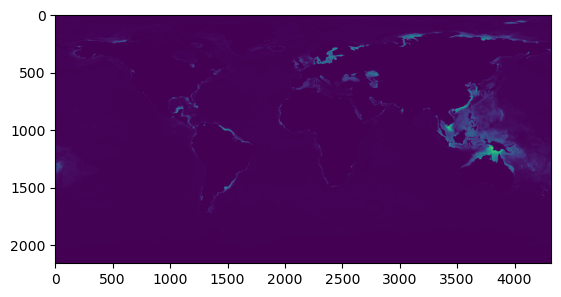

In [13]:
import matplotlib.pyplot as plt
plt.imshow(MAR_plot)

In [ ]:
sediment_budgets = [
    22.66, # prediction_map_MAR_entire_MTL_n_1.npy
    25.14, # prediction_map_MAR_entire_MTL_n_2.npy
    23.93, # prediction_map_MAR_entire_MTL_n_3.npy
    24.20, # prediction_map_MAR_entire_MTL_n_6.npy
    23.36, # prediction_map_MAR_entire_MTL_n_7.npy
    21.69, # prediction_map_MAR_entire_MTL_n_8.npy
    21.60, # prediction_map_MAR_entire_MTL_n_9.npy
    23.50, # prediction_map_MAR_entire_MTL_n_11.npy
    23.83, # prediction_map_MAR_entire_MTL_n_12.npy
    22.10, # prediction_map_MAR_entire_MTL_n_13.npy
    21.97, # prediction_map_MAR_entire_MTL_n_16.npy
    22.97, # prediction_map_MAR_entire_MTL_n_17.npy
    24.78, # prediction_map_MAR_entire_MTL_n_18.npy
    24.36, # prediction_map_MAR_entire_MTL_n_19.npy
    21.18, # prediction_map_MAR_entire_MTL_n_21.npy
    24.31, # prediction_map_MAR_entire_MTL_n_22.npy
    22.78, # prediction_map_MAR_entire_MTL_n_23.npy
    26.67, # prediction_map_MAR_entire_MTL_n_24.npy
    23.62, # prediction_map_MAR_entire_MTL_n_25.npy
    22.54, # prediction_map_MAR_entire_MTL_n_26.npy
    31.29, # prediction_map_MAR_entire_MTL_n_27.npy
    31.48, # prediction_map_MAR_entire_MTL_n_28.npy
    33.95, # prediction_map_MAR_entire_MTL_n_29.npy
    30.26, # prediction_map_MAR_entire_MTL_n_30.npy
]


                                         Layer Widths  \
0                                           [2, 2, 2]   
1                                           [4, 4, 4]   
2                                           [8, 4, 2]   
3                                       [16, 8, 4, 2]   
4                                         [32, 16, 8]   
5                                      [32, 16, 8, 4]   
6                                   [32, 16, 8, 4, 2]   
7                                [32, 32, 32, 32, 32]   
8                                        [64, 64, 64]   
9                            [32, 32, 32, 32, 32, 32]   
10                                      [128, 64, 32]   
11                               [64, 64, 64, 64, 64]   
12                                    [128, 128, 128]   
13                           [64, 64, 64, 64, 64, 64]   
14                             [256, 128, 64, 32, 16]   
15                          [256, 128, 64, 32, 16, 8]   
16                       [256, 

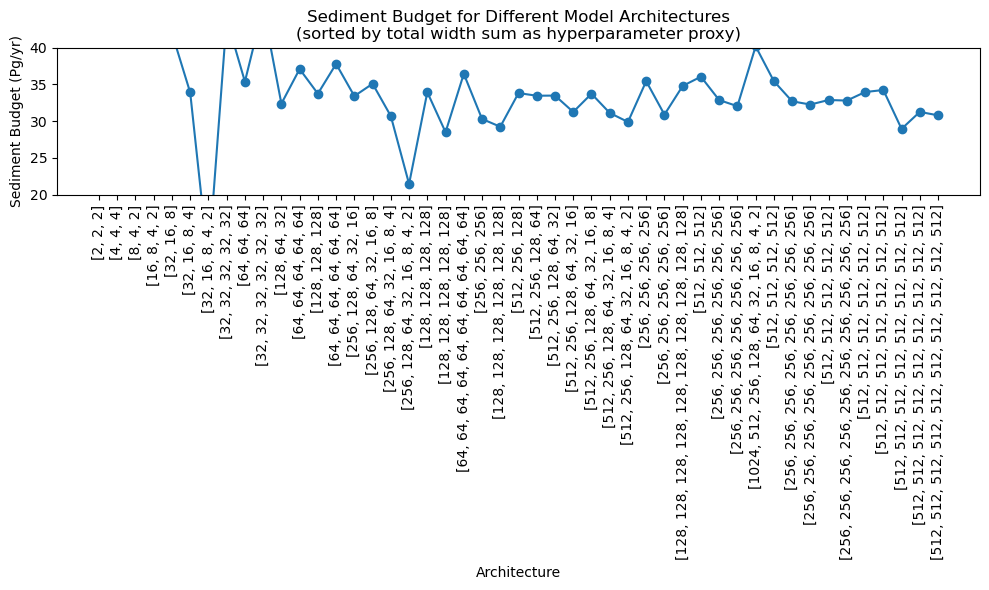

In [35]:
import pandas as pd
import ast
import re

# The original text output as a multiline string

# sediment_budget_text = """
# prediction_map_SedRate_entire_supervised_[1024, 512, 256, 128, 64, 32, 16, 8, 4, 2].npy: Global sediment budget = 40.19 Pg/yr 
# prediction_map_SedRate_entire_supervised_[128, 128, 128, 128, 128, 128, 128, 128, 128, 128].npy: Global sediment budget = 34.80 Pg/yr 
# prediction_map_SedRate_entire_supervised_[128, 128, 128, 128, 128, 128].npy: Global sediment budget = 29.25 Pg/yr 
# prediction_map_SedRate_entire_supervised_[128, 128, 128, 128, 128].npy: Global sediment budget = 28.51 Pg/yr 
# prediction_map_SedRate_entire_supervised_[128, 128, 128, 128].npy: Global sediment budget = 33.95 Pg/yr 
# prediction_map_SedRate_entire_supervised_[128, 128, 128].npy: Global sediment budget = 33.75 Pg/yr 
# prediction_map_SedRate_entire_supervised_[128, 64, 32].npy: Global sediment budget = 32.39 Pg/yr 
# prediction_map_SedRate_entire_supervised_[16, 8, 4, 2].npy: Global sediment budget = 47.37 Pg/yr 
# prediction_map_SedRate_entire_supervised_[2, 2, 2].npy: Global sediment budget = 61.89 Pg/yr 
# prediction_map_SedRate_entire_supervised_[256, 128, 64, 32, 16, 8, 4, 2].npy: Global sediment budget = 21.46 Pg/yr 
# prediction_map_SedRate_entire_supervised_[256, 128, 64, 32, 16, 8, 4].npy: Global sediment budget = 30.70 Pg/yr 
# prediction_map_SedRate_entire_supervised_[256, 128, 64, 32, 16, 8].npy: Global sediment budget = 35.10 Pg/yr 
# prediction_map_SedRate_entire_supervised_[256, 128, 64, 32, 16].npy: Global sediment budget = 33.42 Pg/yr 
# prediction_map_SedRate_entire_supervised_[256, 256, 256, 256, 256, 256, 256, 256, 256, 256].npy: Global sediment budget = 32.81 Pg/yr 
# prediction_map_SedRate_entire_supervised_[256, 256, 256, 256, 256, 256, 256, 256, 256].npy: Global sediment budget = 32.27 Pg/yr 
# prediction_map_SedRate_entire_supervised_[256, 256, 256, 256, 256, 256, 256, 256].npy: Global sediment budget = 32.71 Pg/yr 
# prediction_map_SedRate_entire_supervised_[256, 256, 256, 256, 256, 256, 256].npy: Global sediment budget = 32.05 Pg/yr 
# prediction_map_SedRate_entire_supervised_[256, 256, 256, 256, 256, 256].npy: Global sediment budget = 32.88 Pg/yr 
# prediction_map_SedRate_entire_supervised_[256, 256, 256, 256, 256].npy: Global sediment budget = 30.90 Pg/yr 
# prediction_map_SedRate_entire_supervised_[256, 256, 256, 256].npy: Global sediment budget = 35.45 Pg/yr 
# prediction_map_SedRate_entire_supervised_[256, 256, 256].npy: Global sediment budget = 30.31 Pg/yr 
# prediction_map_SedRate_entire_supervised_[32, 16, 8, 4, 2].npy: Global sediment budget = 10.85 Pg/yr 
# prediction_map_SedRate_entire_supervised_[32, 16, 8, 4].npy: Global sediment budget = 33.91 Pg/yr 
# prediction_map_SedRate_entire_supervised_[32, 16, 8].npy: Global sediment budget = 41.99 Pg/yr 
# prediction_map_SedRate_entire_supervised_[32, 32, 32, 32, 32, 32].npy: Global sediment budget = 45.44 Pg/yr 
# prediction_map_SedRate_entire_supervised_[32, 32, 32, 32, 32].npy: Global sediment budget = 43.91 Pg/yr 
# prediction_map_SedRate_entire_supervised_[4, 4, 4].npy: Global sediment budget = 49.36 Pg/yr 
# prediction_map_SedRate_entire_supervised_[512, 256, 128, 64, 32, 16, 8, 4, 2].npy: Global sediment budget = 29.90 Pg/yr 
# prediction_map_SedRate_entire_supervised_[512, 256, 128, 64, 32, 16, 8, 4].npy: Global sediment budget = 31.13 Pg/yr 
# prediction_map_SedRate_entire_supervised_[512, 256, 128, 64, 32, 16, 8].npy: Global sediment budget = 33.74 Pg/yr 
# prediction_map_SedRate_entire_supervised_[512, 256, 128, 64, 32, 16].npy: Global sediment budget = 31.26 Pg/yr 
# prediction_map_SedRate_entire_supervised_[512, 256, 128, 64, 32].npy: Global sediment budget = 33.49 Pg/yr 
# prediction_map_SedRate_entire_supervised_[512, 256, 128, 64].npy: Global sediment budget = 33.47 Pg/yr 
# prediction_map_SedRate_entire_supervised_[512, 256, 128].npy: Global sediment budget = 33.83 Pg/yr 
# prediction_map_SedRate_entire_supervised_[512, 512, 512, 512, 512, 512, 512, 512, 512, 512].npy: Global sediment budget = 30.80 Pg/yr 
# prediction_map_SedRate_entire_supervised_[512, 512, 512, 512, 512, 512, 512, 512, 512].npy: Global sediment budget = 31.27 Pg/yr 
# prediction_map_SedRate_entire_supervised_[512, 512, 512, 512, 512, 512, 512, 512].npy: Global sediment budget = 28.96 Pg/yr 
# prediction_map_SedRate_entire_supervised_[512, 512, 512, 512, 512, 512, 512].npy: Global sediment budget = 34.25 Pg/yr 
# prediction_map_SedRate_entire_supervised_[512, 512, 512, 512, 512, 512].npy: Global sediment budget = 33.97 Pg/yr 
# prediction_map_SedRate_entire_supervised_[512, 512, 512, 512, 512].npy: Global sediment budget = 32.89 Pg/yr 
# prediction_map_SedRate_entire_supervised_[512, 512, 512, 512].npy: Global sediment budget = 35.45 Pg/yr 
# prediction_map_SedRate_entire_supervised_[512, 512, 512].npy: Global sediment budget = 36.06 Pg/yr 
# prediction_map_SedRate_entire_supervised_[64, 64, 64, 64, 64, 64, 64, 64, 64, 64].npy: Global sediment budget = 36.45 Pg/yr 
# prediction_map_SedRate_entire_supervised_[64, 64, 64, 64, 64, 64].npy: Global sediment budget = 37.80 Pg/yr 
# prediction_map_SedRate_entire_supervised_[64, 64, 64, 64, 64].npy: Global sediment budget = 37.10 Pg/yr 
# prediction_map_SedRate_entire_supervised_[64, 64, 64].npy: Global sediment budget = 35.39 Pg/yr 
# prediction_map_SedRate_entire_supervised_[8, 4, 2].npy: Global sediment budget = 43.15 Pg/yr 
# """
# Use the actual output files from the MTL runs instead. This block defines only the filenames; 
# they will be loaded and processed programmatically below.
mtl_marnpy_files = [
    "prediction_map_MAR_entire_MTL_n_1.npy",
    "prediction_map_MAR_entire_MTL_n_2.npy",
    "prediction_map_MAR_entire_MTL_n_3.npy",
    "prediction_map_MAR_entire_MTL_n_6.npy",
    "prediction_map_MAR_entire_MTL_n_7.npy",
    "prediction_map_MAR_entire_MTL_n_8.npy",
    "prediction_map_MAR_entire_MTL_n_9.npy",
    "prediction_map_MAR_entire_MTL_n_11.npy",
    "prediction_map_MAR_entire_MTL_n_12.npy",
    "prediction_map_MAR_entire_MTL_n_13.npy",
    "prediction_map_MAR_entire_MTL_n_16.npy",
    "prediction_map_MAR_entire_MTL_n_17.npy",
    "prediction_map_MAR_entire_MTL_n_18.npy",
    "prediction_map_MAR_entire_MTL_n_19.npy",
    "prediction_map_MAR_entire_MTL_n_21.npy",
    "prediction_map_MAR_entire_MTL_n_22.npy",
    "prediction_map_MAR_entire_MTL_n_23.npy",
    "prediction_map_MAR_entire_MTL_n_24.npy",
    "prediction_map_MAR_entire_MTL_n_25.npy",
    "prediction_map_MAR_entire_MTL_n_26.npy",
    "prediction_map_MAR_entire_MTL_n_27.npy",
    "prediction_map_MAR_entire_MTL_n_28.npy",
    "prediction_map_MAR_entire_MTL_n_29.npy",
    "prediction_map_MAR_entire_MTL_n_30.npy"
]



# Parse the architectures and values
pattern = re.compile(
    r"prediction_map_SedRate_entire_supervised_(\[[\d, ]+\])\.npy: Global sediment budget = ([\d\.]+) Pg/yr"
)

archs = []
budgets = []

# Parse the architectures and values, using a style similar to parse_hyperopt_output
archs = []
arch_strings = []
arch_keys = []
budgets = []

for line in sediment_budget_text.strip().split('\n'):
    m = pattern.search(line)
    if m:
        arch_str = m.group(1).strip()
        arch_list = list(map(int, arch_str.strip("[]").split(",")))
        archs.append(arch_list)
        arch_strings.append("[" + ", ".join(str(int(a)) for a in arch_list) + "]")
        arch_keys.append("-".join(str(int(a)) for a in arch_list))
        budgets.append(float(m.group(2)))

df_sed_budget = pd.DataFrame({
    "Layer Widths": arch_strings,
    "Architecture": arch_keys,
    "architecture": archs,
    "sediment_budget_Pg_per_yr": budgets
})

# Compute total number of NN parameters for each architecture (assuming fully connected layers).
def calculate_num_parameters(architecture, input_dim=139):
    total_params = 0
    num_layers = len(architecture)
    for i in range(num_layers):
        if i == 0:
            total_params += (input_dim + 1) * architecture[i]
        else:
            total_params += (architecture[i - 1] + 1) * architecture[i]
    total_params += architecture[-1]  # Bias for the output layer
    return total_params

df_sed_budget["Num_Parameters"] = df_sed_budget["architecture"].apply(calculate_num_parameters)
df_sed_budget["num_layers"] = df_sed_budget["architecture"].apply(len)
df_sed_budget["total_neurons"] = df_sed_budget["architecture"].apply(lambda x: sum(x))

# Sort primarily by total_neurons (proxy for total hyperparams), secondarily by num_layers
df_sed_budget = df_sed_budget.sort_values(["total_neurons", "num_layers"]).reset_index(drop=True)

print(df_sed_budget)
import matplotlib.pyplot as plt

# Plot the sediment budget for each architecture (sorted by proxy hyperparams)
plt.figure(figsize=(10,6))
plt.plot(df_sed_budget["Layer Widths"], df_sed_budget["sediment_budget_Pg_per_yr"], marker='o', linestyle='-')
plt.xticks(rotation=90)
plt.xlabel('Architecture')
plt.ylabel('Sediment Budget (Pg/yr)')
plt.title('Sediment Budget for Different Model Architectures\n(sorted by total width sum as hyperparameter proxy)')
plt.tight_layout()
plt.ylim([20,40])
plt.show()
